In [ ]:
!pip -q install control

In [ ]:
#Importación de librerías
import numpy as np
import scipy as sp
import control as ct
import matplotlib.pyplot as plt
import pandas as pd

from scipy.optimize import least_squares

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'font.size': 12,
    'axes.grid': True,
    'figure.dpi': 120
})

In [ ]:
#Modelo nominal de la planta
# Parámetros físicos
m = 0.033
b = 0.15
g = 9.8

# Dinámica angular
q0 = 33.1549
q1 = 9.736
ks = 11.4345

# Variable de Laplace
s = ct.TransferFunction.s

# Modelo nominal de velocidad
Gv = g*ks / ((s + b/m)*(s**2 + q1*s + q0))

# Modelo nominal de posición
G = Gv/s

print("Modelo nominal de posición:")
print(G)

print("Polos:")
print(ct.poles(G))

Modelo nominal de posición:
<TransferFunction>: sys[13]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                  112.1
  -------------------------------------
  s^4 + 14.28 s^3 + 77.41 s^2 + 150.7 s
Polos:
[-4.868     +3.07530096j -4.868     -3.07530096j -4.54545455+0.j
  0.        +0.j        ]


# Reducción del modelo para la sintonización IMC-PID

El modelo nominal de posición del sistema
barra-carrito presenta un integrador y tres
polos asociados a las dinámicas mecánica y angular.

Para aplicar reglas de sintonización IMC-PID,
se propone obtener un modelo de orden reducido
que conserve el integrador de la planta.

La aproximación será validada frente al modelo
nominal completo antes de proceder al diseño
del controlador.

Polos del modelo nominal:
-4.868000 +3.075301j
-4.868000 -3.075301j
-4.545455 +0.000000j
0.000000 +0.000000j


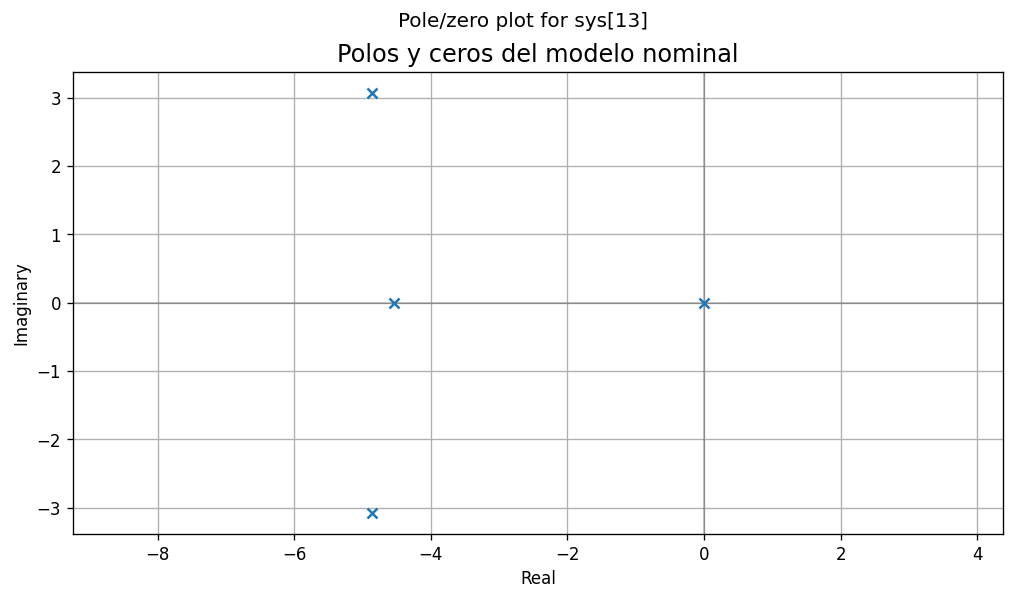

In [ ]:
#Análisis de los polos del modelo nominal
polos = ct.poles(G)

print("Polos del modelo nominal:")

for p in polos:
    print(f"{p.real:.6f} {p.imag:+.6f}j")

ct.pole_zero_plot(G)
plt.title("Polos y ceros del modelo nominal")
plt.grid(True)
plt.show()

Ganancia estática de velocidad: 0.743564


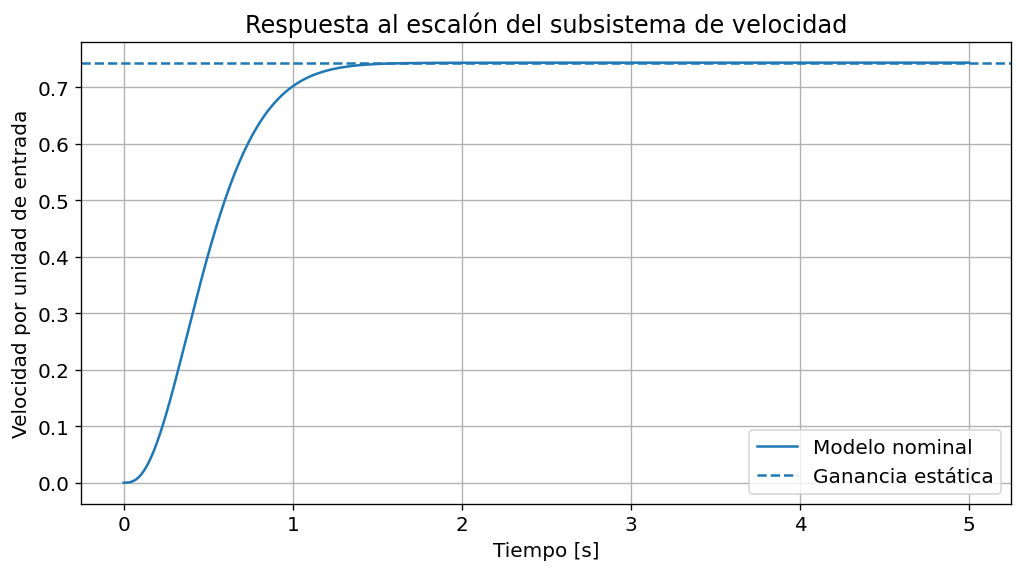

In [ ]:
#Separación del integrador
Kv = float(ct.dcgain(Gv))

print(f"Ganancia estática de velocidad: {Kv:.6f}")

t_red = np.linspace(0, 5, 2501)

_, v_nom = ct.step_response(Gv, t_red)

plt.figure()
plt.plot(t_red, v_nom, label="Modelo nominal")
plt.axhline(Kv, linestyle="--", label="Ganancia estática")

plt.xlabel("Tiempo [s]")
plt.ylabel("Velocidad por unidad de entrada")
plt.title("Respuesta al escalón del subsistema de velocidad")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Aproximación de la dinámica de velocidad y posterior recuperación del integrador.
def respuesta_reducida(t, tau):
    return Kv * (1 - np.exp(-t/tau))


def residuos(p):
    tau = p[0]
    return respuesta_reducida(t_red, tau) - v_nom


ajuste = least_squares(
    residuos,
    x0=[0.5],
    bounds=([1e-4], [10])
)

tau_red = ajuste.x[0]

Gv_red = Kv / (tau_red*s + 1)
G_red = Gv_red / s

print(f"K = {Kv:.8f}")
print(f"Tau = {tau_red:.8f} s")

print("Modelo reducido de posición:")
print(G_red)

K = 0.74356376
Tau = 0.53521814 s
Modelo reducido de posición:
<TransferFunction>: sys[21]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

      0.7436
  --------------
  0.5352 s^2 + s


In [ ]:
#Primera aproximación de orden reducido - ajustar tau por mínimos cuadrados.
def respuesta_reducida(t, tau):
    return Kv * (1 - np.exp(-t/tau))


def residuos(p):
    tau = p[0]
    return respuesta_reducida(t_red, tau) - v_nom


ajuste = least_squares(
    residuos,
    x0=[0.5],
    bounds=([1e-4], [10])
)

tau_red = ajuste.x[0]

Gv_red = Kv / (tau_red*s + 1)
G_red = Gv_red / s

print(f"K = {Kv:.8f}")
print(f"Tau = {tau_red:.8f} s")

print("Modelo reducido de posición:")
print(G_red)

K = 0.74356376
Tau = 0.53521814 s
Modelo reducido de posición:
<TransferFunction>: sys[28]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

      0.7436
  --------------
  0.5352 s^2 + s


RMSE: 0.04639201
FIT: 75.01 %


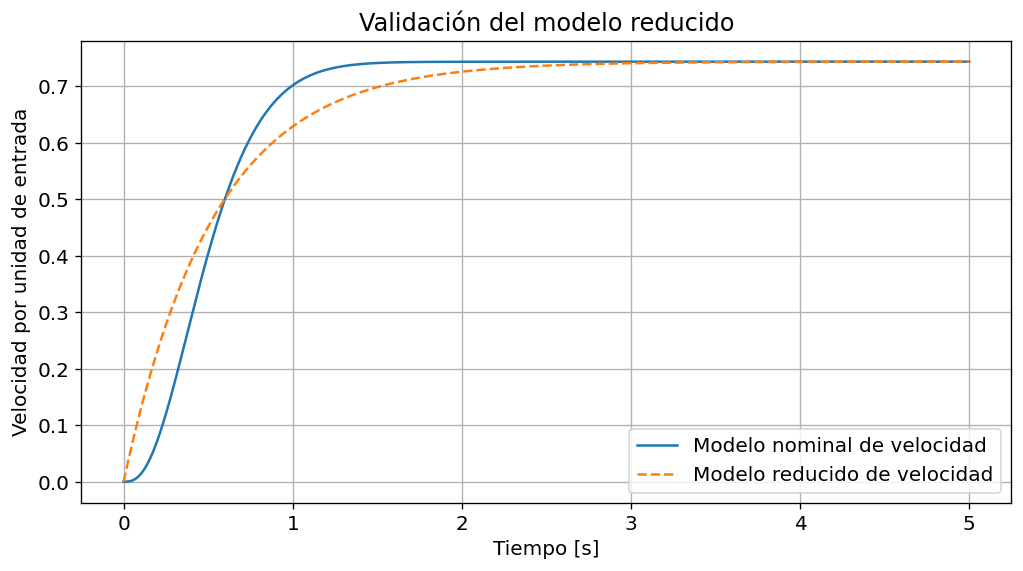

In [ ]:
#Validación temporal de la reducción
_, v_red = ct.step_response(Gv_red, t_red)

rmse = np.sqrt(np.mean((v_nom - v_red)**2))

fit = 100 * (
    1 - np.linalg.norm(v_nom - v_red)
    / np.linalg.norm(v_nom - np.mean(v_nom))
)

print(f"RMSE: {rmse:.8f}")
print(f"FIT: {fit:.2f} %")

plt.figure()

plt.plot(t_red, v_nom,
         label="Modelo nominal de velocidad")

plt.plot(t_red, v_red, "--",
         label="Modelo reducido de velocidad")

plt.xlabel("Tiempo [s]")
plt.ylabel("Velocidad por unidad de entrada")
plt.title("Validación del modelo reducido")
plt.legend()
plt.grid(True)
plt.show()

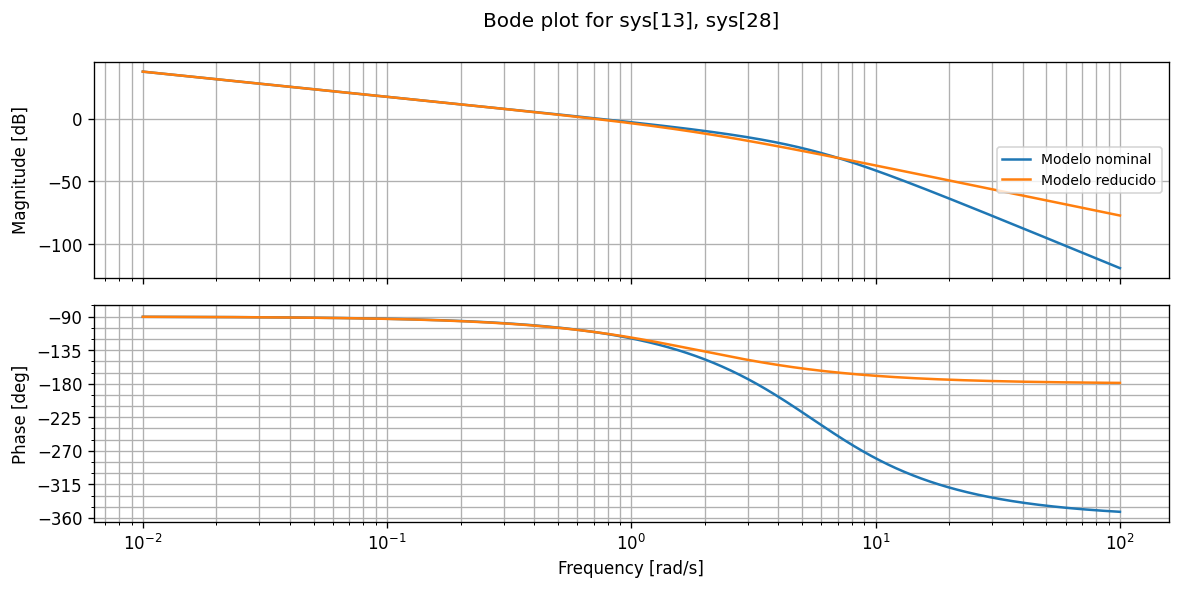

In [ ]:
#Comparación frecuencial
w = np.logspace(-2, 2, 1000)

ct.bode_plot(
    [G, G_red],
    omega=w,
    dB=True,
    deg=True,
    label=["Modelo nominal", "Modelo reducido"]
)

plt.show()

In [ ]:
#Reducción incorporando un retardo equivalente
def respuesta_con_retardo(t, tau, L):

    tiempo = np.maximum(t - L, 0)

    return Kv * (1 - np.exp(-tiempo/tau))


def residuos_retardo(p):

    tau, L = p

    return respuesta_con_retardo(t_red, tau, L) - v_nom


ajuste_retardo = least_squares(
    residuos_retardo,
    x0=[tau_red, 0.1],
    bounds=([1e-4, 0], [10, 5])
)

tau_ret, L_ret = ajuste_retardo.x

v_ret = respuesta_con_retardo(t_red, tau_ret, L_ret)

print(f"K = {Kv:.8f}")
print(f"Tau = {tau_ret:.8f} s")
print(f"L = {L_ret:.8f} s")

K = 0.74356376
Tau = 0.32329867 s
L = 0.21481838 s


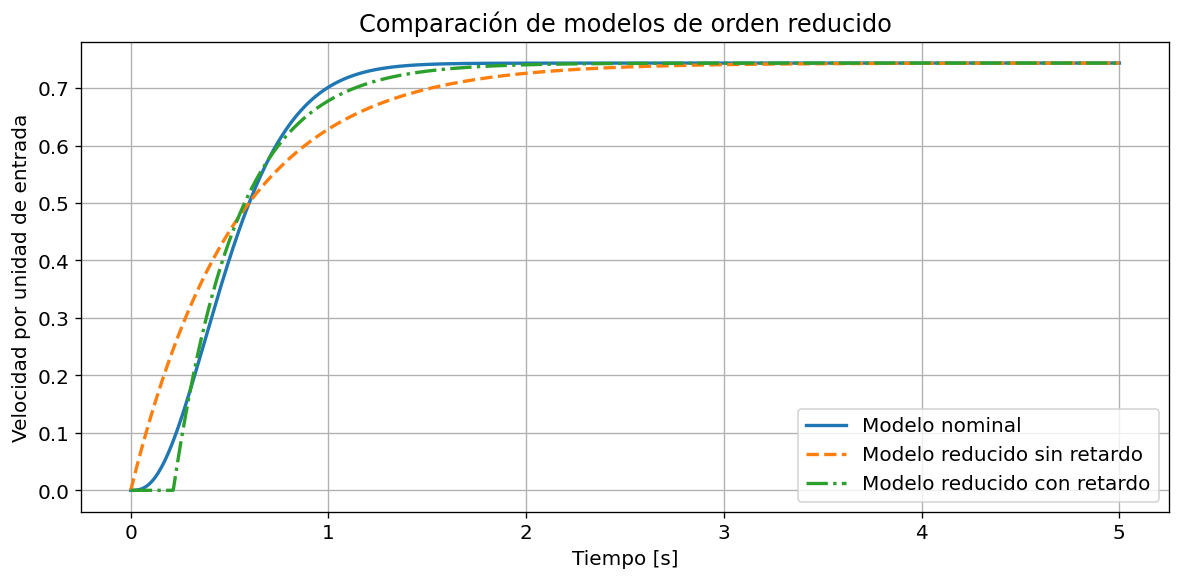

In [ ]:
#Comparación de los tres modelos
plt.figure(figsize=(10, 5))

plt.plot(
    t_red, v_nom,
    linewidth=2,
    label="Modelo nominal"
)

plt.plot(
    t_red, v_red, "--",
    linewidth=2,
    label="Modelo reducido sin retardo"
)

plt.plot(
    t_red, v_ret, "-.",
    linewidth=2,
    label="Modelo reducido con retardo"
)

plt.xlabel("Tiempo [s]")
plt.ylabel("Velocidad por unidad de entrada")
plt.title("Comparación de modelos de orden reducido")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Comparación cuantitativa
import pandas as pd

def calcular_fit(y, yh):

    return 100 * (
        1 - np.linalg.norm(y - yh)
        / np.linalg.norm(y - np.mean(y))
    )


def calcular_rmse(y, yh):

    return np.sqrt(np.mean((y - yh)**2))


resultados_reduccion = pd.DataFrame({

    "Modelo": [
        "Sin retardo",
        "Con retardo"
    ],

    "K": [Kv, Kv],

    "Tau [s]": [tau_red, tau_ret],

    "L [s]": [0, L_ret],

    "FIT [%]": [
        calcular_fit(v_nom, v_red),
        calcular_fit(v_nom, v_ret)
    ],

    "RMSE": [
        calcular_rmse(v_nom, v_red),
        calcular_rmse(v_nom, v_ret)
    ]
})

display(resultados_reduccion.round(6))

,Modelo,K,Tau [s],L [s],FIT [%],RMSE
0,Sin retardo,0.743564,0.535218,0.000000,75.005611,0.04639201184926743
1,Con retardo,0.743564,0.323299,0.214818,92.377603,0.014147909179570123


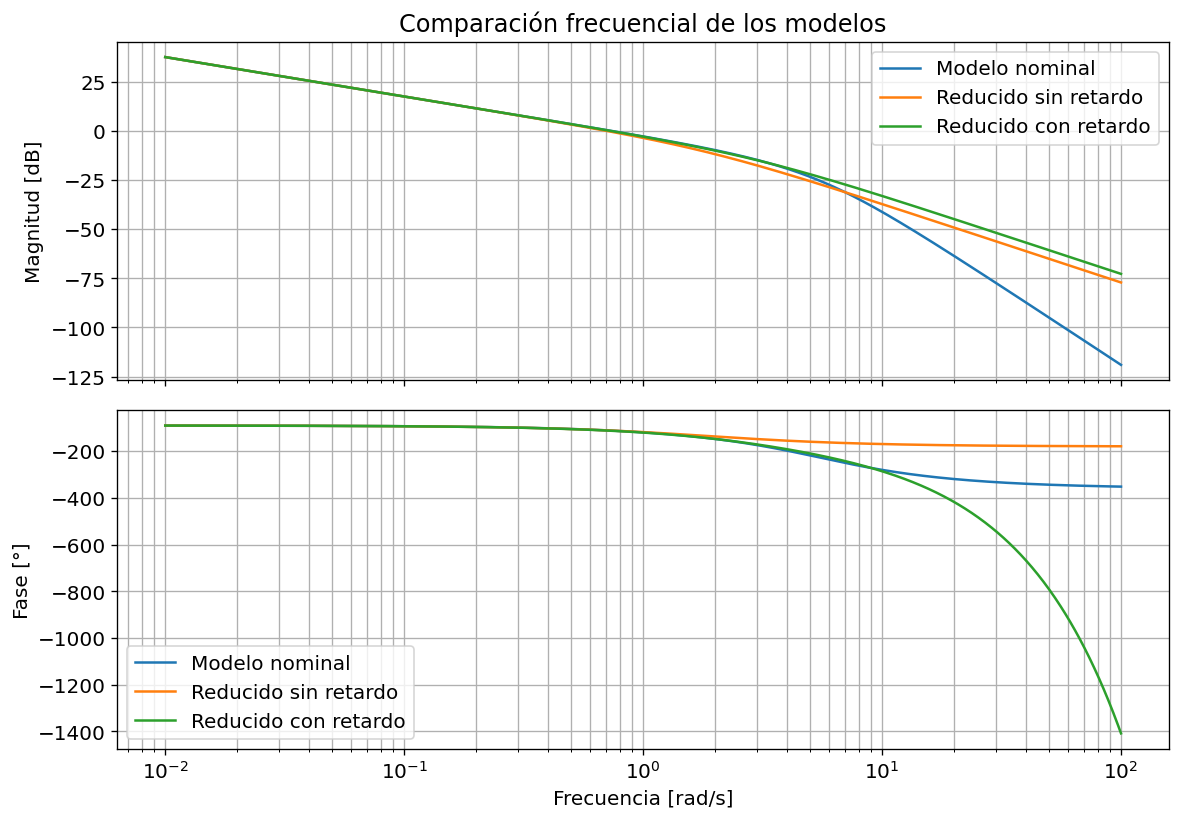

In [ ]:
#Comparación frecuencial con retardo
w = np.logspace(-2, 2, 1000)

jw = 1j*w

H_nom = (
    g*ks /
    (jw*(jw+b/m)*(jw**2+q1*jw+q0))
)

H_red = Kv / (
    jw*(tau_red*jw+1)
)

H_ret = Kv*np.exp(-L_ret*jw) / (
    jw*(tau_ret*jw+1)
)

fig, ax = plt.subplots(2, 1, figsize=(10, 7),
                       sharex=True)

modelos = [
    (H_nom, "Modelo nominal"),
    (H_red, "Reducido sin retardo"),
    (H_ret, "Reducido con retardo")
]

for H, nombre in modelos:

    magnitud = 20*np.log10(np.abs(H))
    fase = np.rad2deg(np.unwrap(np.angle(H)))

    ax[0].semilogx(w, magnitud, label=nombre)
    ax[1].semilogx(w, fase, label=nombre)

ax[0].set_ylabel("Magnitud [dB]")
ax[1].set_ylabel("Fase [°]")
ax[1].set_xlabel("Frecuencia [rad/s]")

ax[0].set_title("Comparación frecuencial de los modelos")

for a in ax:
    a.grid(True, which="both")
    a.legend()

plt.tight_layout()
plt.show()

In [ ]:
#Sintonización SIMC-PID
# Parámetro inicial de sintonización
lambda_c = 0.5

def sintonizar_simc(K, tau, L, lambda_c):

    # PID en forma serie
    Kc = 1 / (K * (lambda_c + L))
    Ti = 4 * (lambda_c + L)
    Td = tau

    # Conversión a PID paralelo
    Kp = Kc * (1 + Td/Ti)
    Ki = Kc / Ti
    Kd = Kc * Td

    return Kc, Ti, Td, Kp, Ki, Kd


Kc, Ti, Td, Kp, Ki, Kd = sintonizar_simc(
    Kv, tau_ret, L_ret, lambda_c
)

print("PID EN FORMA SERIE")
print(f"Kc = {Kc:.8f}")
print(f"Ti = {Ti:.8f} s")
print(f"Td = {Td:.8f} s")

print("\nPID EN FORMA PARALELA")
print(f"Kp = {Kp:.8f}")
print(f"Ki = {Ki:.8f}")
print(f"Kd = {Kd:.8f}")

PID EN FORMA SERIE
Kc = 1.88142139
Ti = 2.85927352 s
Td = 0.32329867 s

PID EN FORMA PARALELA
Kp = 2.09415411
Ki = 0.65800679
Kd = 0.60826104


In [ ]:
#Discretización del controlador
# Mismo período utilizado en el diseño IMC
Ts = 0.02

z = ct.TransferFunction.z

# Conversión a los parámetros del PID incremental
kp = Kp
ki = Ki * Ts / Kp
kd = Kd / (Kp * Ts)

R = ct.TransferFunction(
    kp * np.array([
        1 + ki + kd,
        -(1 + 2*kd),
        kd
    ]),
    [1, -1, 0],
    Ts
)

print("PARÁMETROS DEL PID DISCRETO")
print(f"kp = {kp:.8f}")
print(f"ki = {ki:.8f}")
print(f"kd = {kd:.8f}")

print("\nControlador discreto:")
print(R)

PARÁMETROS DEL PID DISCRETO
kp = 2.09415411
ki = 0.00628423
kd = 14.52283379

Controlador discreto:
<TransferFunction>: sys[32]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

  32.52 z^2 - 62.92 z + 30.41
  ---------------------------
            z^2 - z


Polos de lazo cerrado:
0.00002407 +0.00000000j
0.86171263 +0.00000000j
0.94838121 +0.05681721j
0.94838121 -0.05681721j
0.97613226 +0.00000000j
0.98947412 +0.00000000j

Radio espectral = 0.98947412
Lazo cerrado estable: True


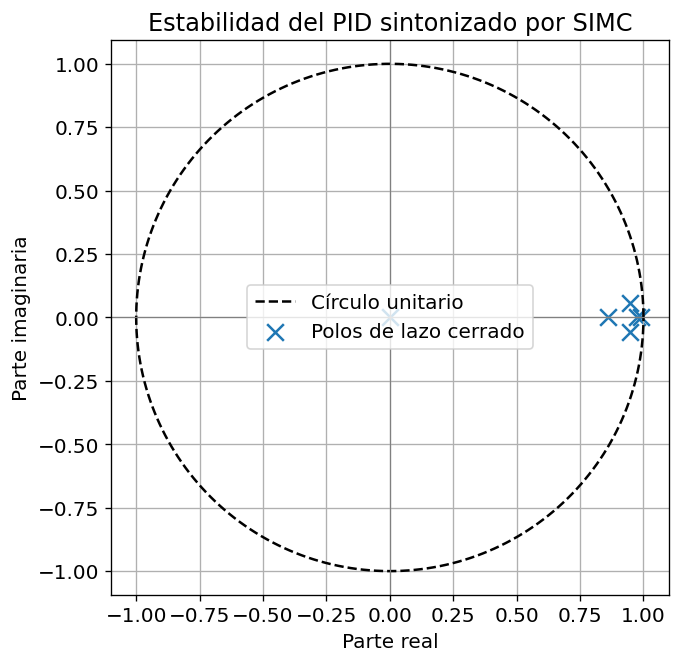

In [ ]:
#Verificación de estabilidad
# Discretización ZOH de la planta completa
Gd = ct.c2d(G, Ts, method="zoh")

# Realizaciones en espacio de estados
P = ct.ss(Gd)
C = ct.ss(R)

# Lazo cerrado sin reducción de estados
LC = ct.feedback(P*C, 1)

polos_LC = ct.poles(LC)
rho = np.max(np.abs(polos_LC))

estable = rho < 1

print("Polos de lazo cerrado:")

for p in polos_LC:
    print(f"{p.real:.8f} {p.imag:+.8f}j")

print(f"\nRadio espectral = {rho:.8f}")
print(f"Lazo cerrado estable: {estable}")

# Mapa de polos
ang = np.linspace(0, 2*np.pi, 500)

plt.figure(figsize=(6, 6))

plt.plot(
    np.cos(ang), np.sin(ang),
    "k--", label="Círculo unitario"
)

plt.scatter(
    polos_LC.real,
    polos_LC.imag,
    marker="x",
    s=100,
    label="Polos de lazo cerrado"
)

plt.axhline(0, color="gray", linewidth=0.7)
plt.axvline(0, color="gray", linewidth=0.7)

plt.xlabel("Parte real")
plt.ylabel("Parte imaginaria")
plt.title("Estabilidad del PID sintonizado por SIMC")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
#Transferencias del lazo cerrado
# Transferencias del sistema realimentado

# Referencia -> posición
T_simc = ct.feedback(P*C, 1)

# Referencia -> acción de control
UR_simc = ct.feedback(C, P)

# Perturbación de entrada -> posición
GS_simc = ct.feedback(P, C)

# Perturbación de entrada -> acción de control
UD_simc = -C*GS_simc

print("Transferencias obtenidas.")

Transferencias obtenidas.


In [ ]:
#Simulación temporal
t_simc = np.arange(0, 60 + Ts/2, Ts)

ref_simc = 0.1*(t_simc >= 0.5)

du_simc = np.deg2rad(1)*(
    (t_simc >= 5) & (t_simc < 6)
)

# Seguimiento de referencia
_, y_simc = ct.forced_response(
    T_simc, t_simc, ref_simc
)

_, u_simc = ct.forced_response(
    UR_simc, t_simc, ref_simc
)

# Respuesta a la perturbación
_, yd_simc = ct.forced_response(
    GS_simc, t_simc, du_simc
)

_, ud_simc = ct.forced_response(
    UD_simc, t_simc, du_simc
)

# Superposición
y_total_simc = y_simc + yd_simc
u_total_simc = u_simc + ud_simc

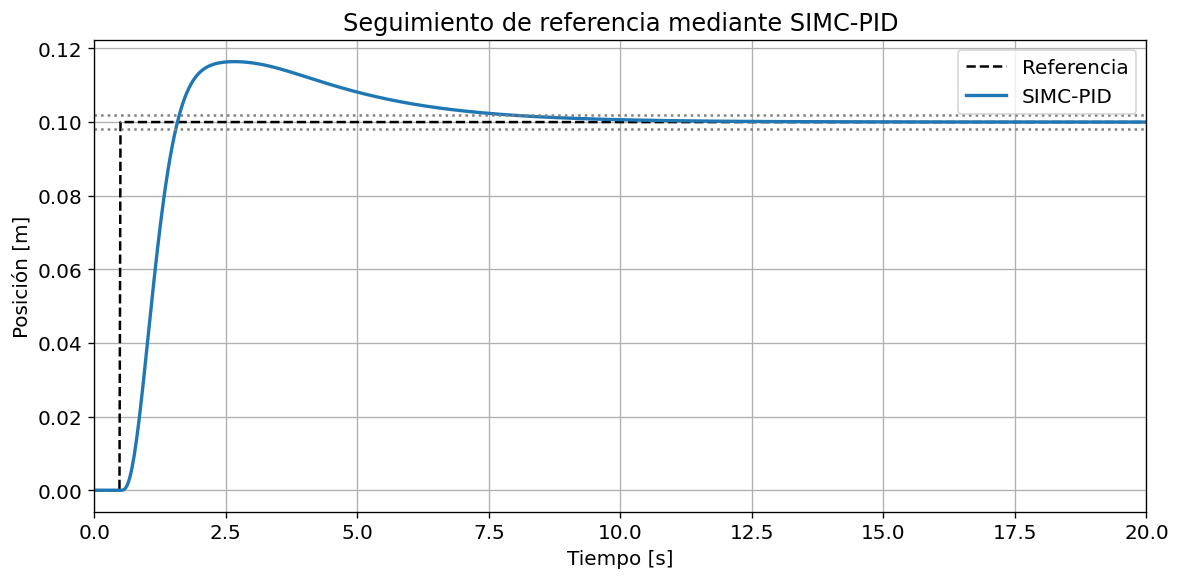

In [ ]:
#Seguimiento de referencia
plt.figure(figsize=(10, 5))

plt.plot(
    t_simc, ref_simc, "k--",
    label="Referencia"
)

plt.plot(
    t_simc, y_simc,
    linewidth=2,
    label="SIMC-PID"
)

plt.axhline(0.102, color="gray", linestyle=":")
plt.axhline(0.098, color="gray", linestyle=":")

plt.xlabel("Tiempo [s]")
plt.ylabel("Posición [m]")
plt.title("Seguimiento de referencia mediante SIMC-PID")

plt.xlim(0, 20)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

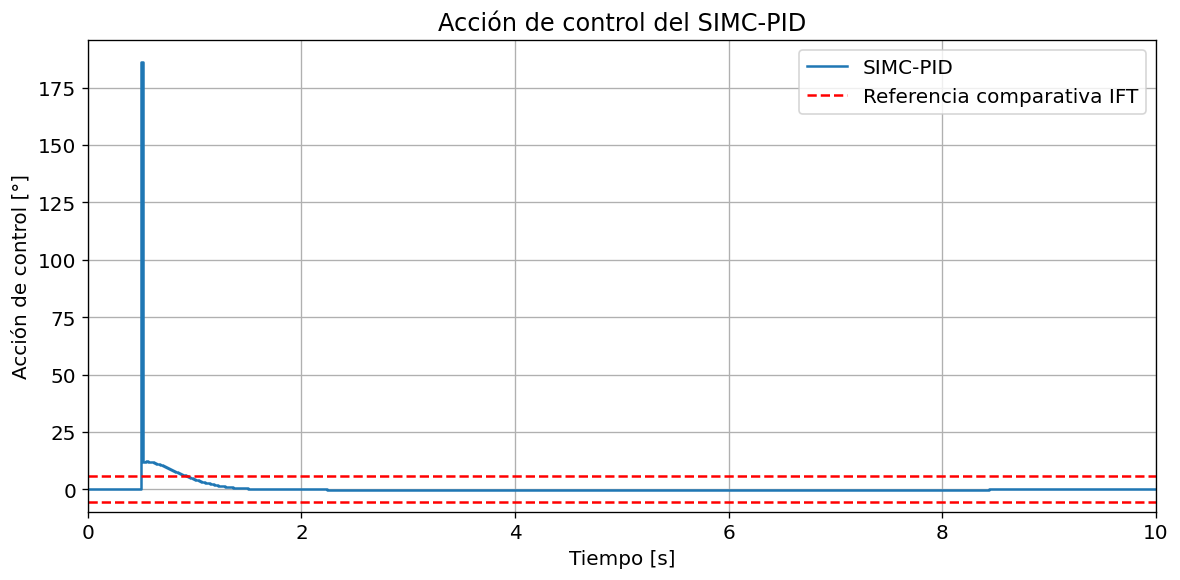

In [ ]:
#Acción de control
plt.figure(figsize=(10, 5))

plt.step(
    t_simc, np.rad2deg(u_simc),
    where="post",
    linewidth=1.5,
    label="SIMC-PID"
)

plt.axhline(
    5.6975, color="red", linestyle="--",
    label="Referencia comparativa IFT"
)

plt.axhline(
    -5.6975, color="red", linestyle="--"
)

plt.xlabel("Tiempo [s]")
plt.ylabel("Acción de control [°]")
plt.title("Acción de control del SIMC-PID")

plt.xlim(0, 10)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

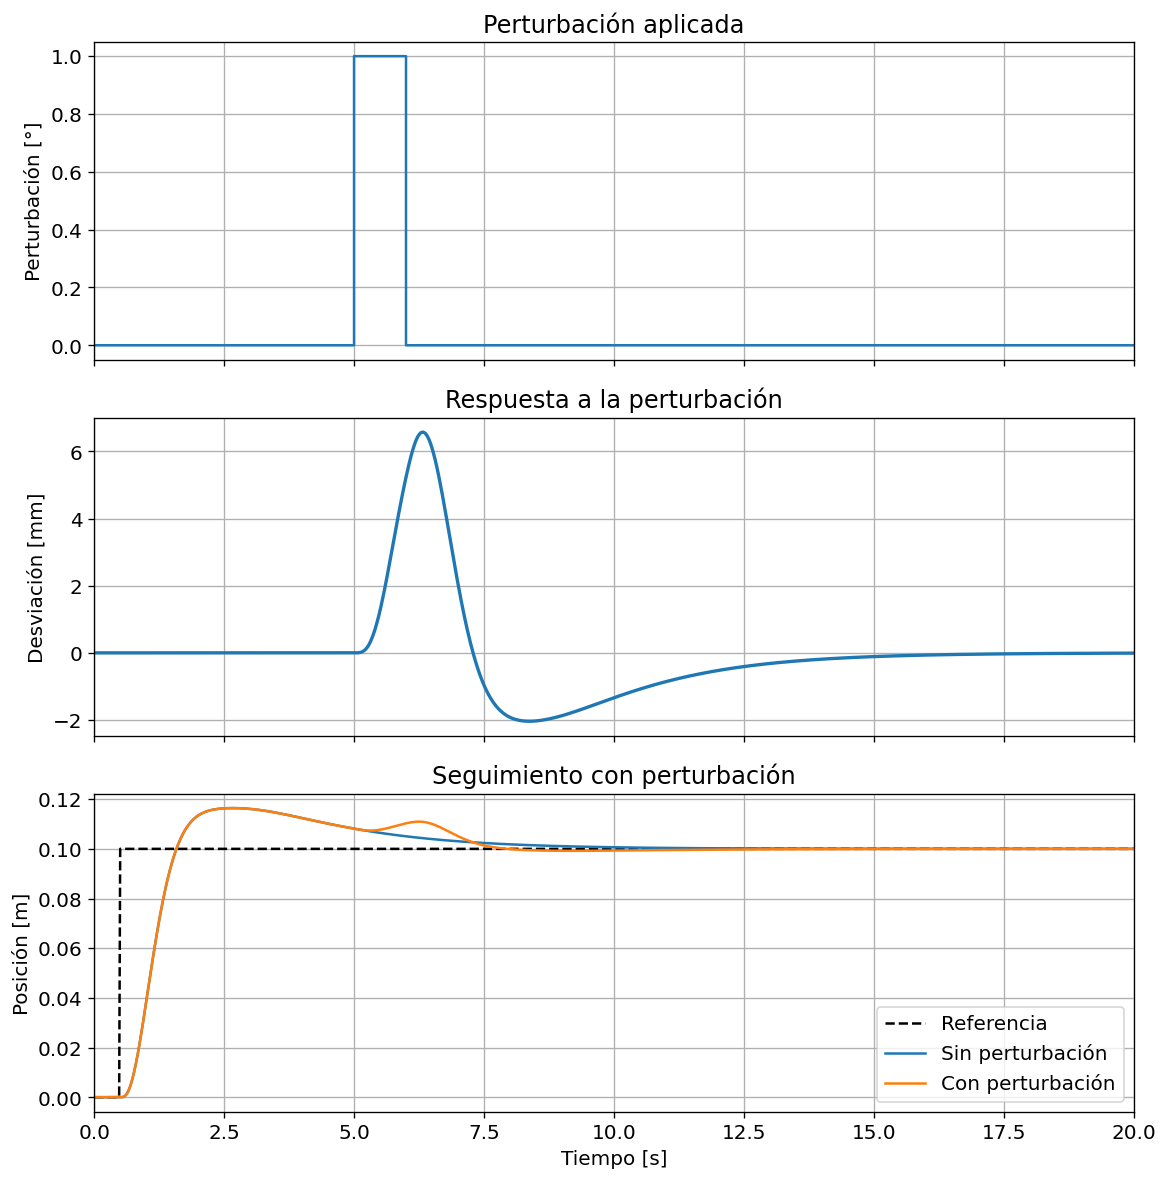

In [ ]:
#Rechazo de perturbaciones
fig, ax = plt.subplots(3, 1, figsize=(10, 10),
                       sharex=True)

# Perturbación aplicada
ax[0].step(
    t_simc, np.rad2deg(du_simc),
    where="post"
)

ax[0].set_ylabel("Perturbación [°]")
ax[0].set_title("Perturbación aplicada")

# Contribución de la perturbación
ax[1].plot(
    t_simc, 1000*yd_simc,
    linewidth=2
)

ax[1].set_ylabel("Desviación [mm]")
ax[1].set_title("Respuesta a la perturbación")

# Respuesta total
ax[2].plot(
    t_simc, ref_simc, "k--",
    label="Referencia"
)

ax[2].plot(
    t_simc, y_simc,
    label="Sin perturbación"
)

ax[2].plot(
    t_simc, y_total_simc,
    label="Con perturbación"
)

ax[2].set_ylabel("Posición [m]")
ax[2].set_xlabel("Tiempo [s]")
ax[2].set_title("Seguimiento con perturbación")
ax[2].legend()

for a in ax:
    a.grid(True)
    a.set_xlim(0, 20)

plt.tight_layout()
plt.show()

In [ ]:
#Indicadores de desempeño
def indicadores_control(t, ref, y, u, yd, u_total):

    idx = np.flatnonzero(
        np.abs(ref-ref[0]) > 1e-9
    )[0]

    rf = ref[-1]
    amplitud = abs(rf-ref[0])

    tol = 0.02*amplitud

    # Sobreimpulso
    Mp = 100*max(
        0, np.max(y[idx:])-rf
    )/amplitud

    # Tiempo de establecimiento
    fuera = np.flatnonzero(
        np.abs(y[idx:]-rf) > tol
    )

    if len(fuera) == 0:
        Te = 0.0

    elif fuera[-1] < len(y[idx:])-1:
        Te = t[idx+fuera[-1]+1]-t[idx]

    else:
        Te = np.nan

    return {
        "Sobreimpulso [%]": Mp,
        "Establecimiento [s]": Te,
        "Control máximo [°]":
            np.max(np.abs(np.rad2deg(u))),
        "Control máximo con perturbación [°]":
            np.max(np.abs(np.rad2deg(u_total))),
        "Control RMS [°]":
            np.sqrt(np.mean(np.rad2deg(u)**2)),
        "RMSE referencia [m]":
            np.sqrt(np.mean((ref-y)**2)),
        "Error final [m]": ref[-1]-y[-1],
        "Desviación por perturbación [mm]":
            1000*np.max(np.abs(yd))
    }


metricas_simc = indicadores_control(
    t_simc,
    ref_simc,
    y_simc,
    u_simc,
    yd_simc,
    u_total_simc
)

display(
    pd.DataFrame(
        metricas_simc,
        index=["SIMC-PID"]
    ).T.round(6)
)

,SIMC-PID
Sobreimpulso [%],16.414428
Establecimiento [s],7.320000
Control máximo [°],186.327974
Control máximo con perturbación [°],186.327974
Control RMS [°],3.507259
RMSE referencia [m],0.009380
Error final [m],-0.000000
Desviación por perturbación [mm],6.575548


In [ ]:
#Función general para evaluar el SIMC-PID
def evaluar_simc(lambda_c, planta, t, ref, du):

    Kc, Ti, Td, Kp, Ki, Kd = sintonizar_simc(
        Kv, tau_ret, L_ret, lambda_c
    )

    # Parámetros del PID incremental
    kp = Kp
    ki = Ki*Ts/Kp
    kd = Kd/(Kp*Ts)

    R = ct.TransferFunction(
        kp*np.array([
            1 + ki + kd,
            -(1 + 2*kd),
            kd
        ]),
        [1, -1, 0],
        Ts
    )

    P = ct.ss(planta)
    C = ct.ss(R)

    # Estabilidad sin reducir estados
    T = ct.feedback(P*C, 1)

    polos = ct.poles(T)
    rho = np.max(np.abs(polos))

    resultado = {
        "Lambda_c [s]": lambda_c,
        "kp": kp,
        "ki": ki,
        "kd": kd,
        "Radio espectral": rho,
        "Estable": rho < 1
    }

    if rho >= 1:
        return resultado, None

    # Transferencias internas
    UR = ct.feedback(C, P)
    GS = ct.feedback(P, C)
    UD = -C*GS

    _, y = ct.forced_response(T, t, ref)
    _, u = ct.forced_response(UR, t, ref)

    _, yd = ct.forced_response(GS, t, du)
    _, ud = ct.forced_response(UD, t, du)

    y_total = y + yd
    u_total = u + ud

    resultado.update(
        indicadores_control(
            t, ref, y, u, yd, u_total
        )
    )

    senales = {
        "y": y,
        "u": u,
        "yd": yd,
        "ud": ud,
        "y_total": y_total,
        "u_total": u_total,
        "R": R,
        "polos": polos
    }

    return resultado, senales

In [ ]:
#Barrido del parámetro de sintonización
lambdas_c = [
    0.25, 0.5, 0.75, 1,
    1.5, 2, 3, 4, 6,
    8, 10, 15, 20, 30
]

t_barrido = np.arange(0, 300 + Ts/2, Ts)

ref_barrido = 0.1*(t_barrido >= 0.5)

du_barrido = np.deg2rad(1)*(
    (t_barrido >= 5) &
    (t_barrido < 6)
)

resultados = []
senales_barrido = {}

for lc in lambdas_c:

    resultado, senales = evaluar_simc(
        lc,
        Gd,
        t_barrido,
        ref_barrido,
        du_barrido
    )

    resultados.append(resultado)
    senales_barrido[lc] = senales

tabla_simc = pd.DataFrame(resultados)

display(tabla_simc.round(6))

,Lambda_c [s],kp,ki,kd,Radio espectral,Estable,Sobreimpulso [%],Establecimiento [s],Control máximo [°],Control máximo con perturbación [°],Control RMS [°],RMSE referencia [m],Error final [m],Desviación por perturbación [mm]
0,0.25,3.396439,0.009163,13.770465,0.984538,True,32.58702854253672,4.68,287.613964484042,287.613964484042,2.4179960123167485,0.003845440728656243,-0.000000,5.091023035812005
1,0.50,2.094154,0.006284,14.522834,0.989474,True,16.414427993894794,7.32,186.32797363022632,186.32797363022632,1.5687030602318197,0.004195606174586115,-0.000000,6.575547930908491
2,0.75,1.510686,0.004782,14.915439,0.991963,True,15.617106429929374,10.02,137.79892354354902,137.79892354354902,1.1701332796486874,0.004612686695434735,0.000000,7.536676551567795
3,1.00,1.180713,0.003859,15.156535,0.993477,True,15.145497075107789,12.70,109.32488159736253,109.32488159736253,0.9379234727988283,0.005018725535424466,0.000000,8.21454995254608
4,1.50,0.821231,0.002785,15.437325,0.995238,True,14.64146826281623,18.08,77.35579919860206,77.35579919860206,0.6782080519446713,0.005766967852697424,-0.000000,9.1221994153906
5,2.00,0.629376,0.002178,15.595801,0.996237,True,14.37718279996479,23.48,59.85325258610122,59.85325258610122,0.5362364485845431,0.006438692095057471,-0.000000,9.710220869544667
6,3.00,0.428854,0.001517,15.768494,0.997338,True,14.104411107805511,34.26,41.206434802148415,41.206434802148415,0.38479569505565775,0.007614885105054622,0.000000,10.439008866549173
7,4.00,0.325201,0.001164,15.860782,0.997934,True,13.964844743856299,45.04,31.41829258932237,31.41829258932237,0.3049454823222939,0.008636166902296693,0.000000,10.881113974825478
8,6.00,0.219212,0.000794,15.957405,0.998568,True,13.82316391718355,66.60,21.299400085701045,21.299400085701045,0.22163677987537578,0.01038486091530993,-0.000000,11.400241600547895
9,8.00,0.165324,0.000603,16.007438,0.998902,True,13.751533895545371,88.18,16.11064174928143,16.11064174928143,0.1782303760905315,0.011880306371348329,-0.000000,11.700387471333642


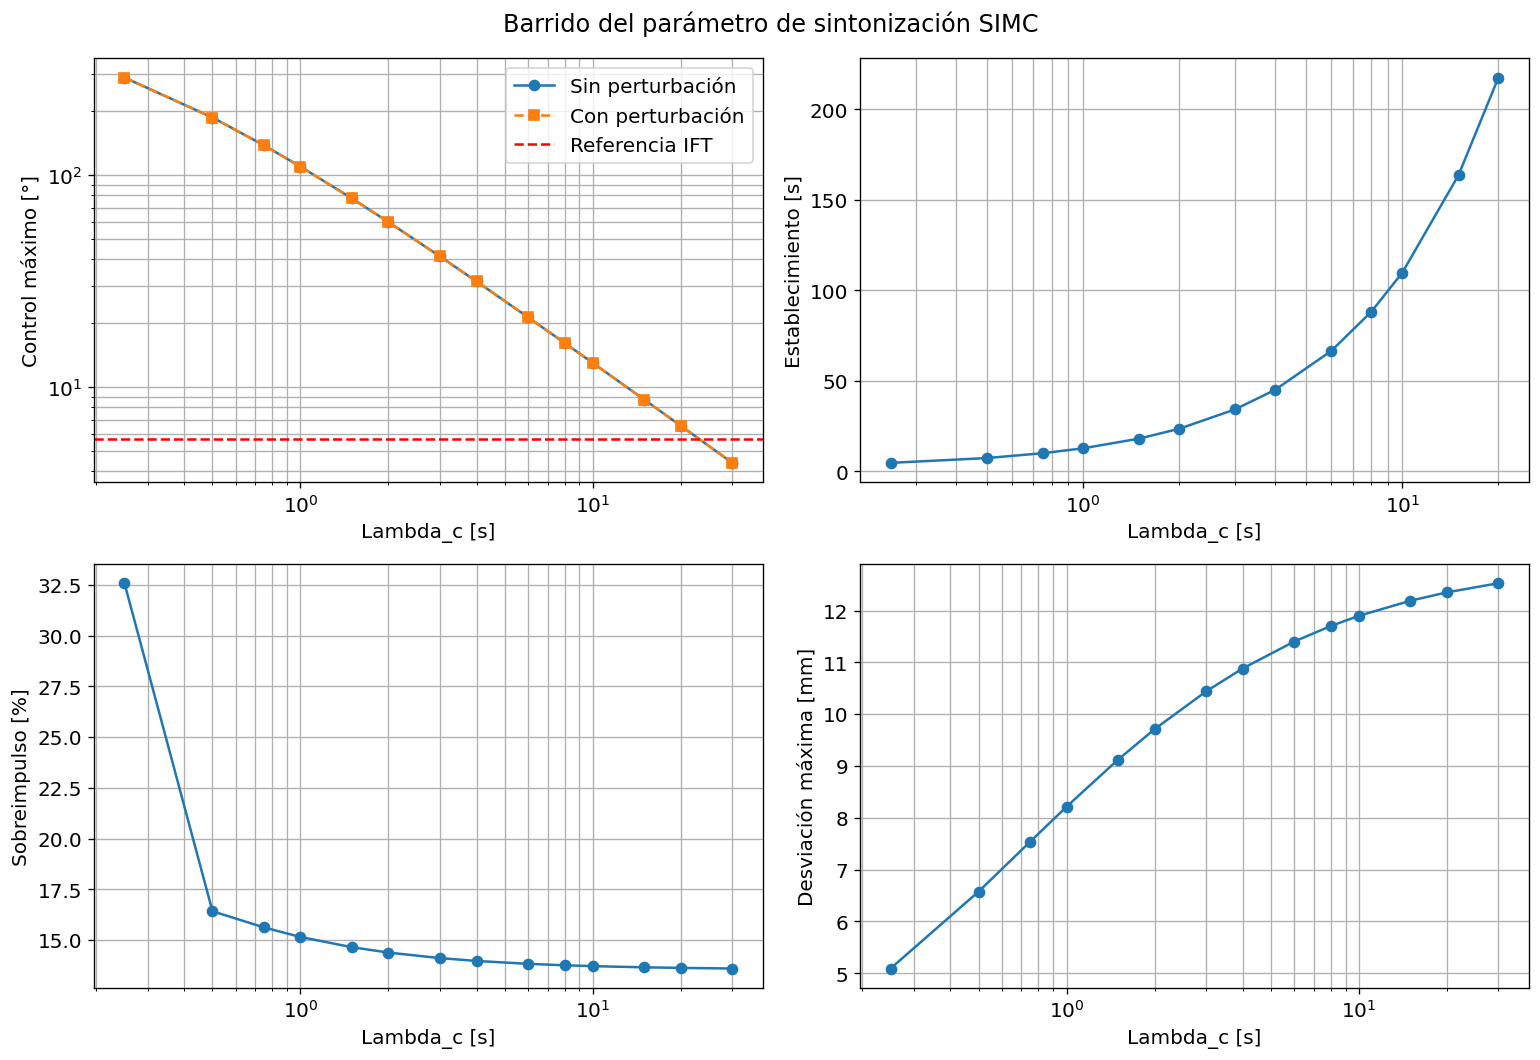

In [ ]:
#Comparación de los indicadores
validos = tabla_simc[
    tabla_simc["Estable"]
].copy()

fig, ax = plt.subplots(
    2, 2, figsize=(13, 9)
)

x = validos["Lambda_c [s]"]

# Acción máxima de control
ax[0, 0].plot(
    x, validos["Control máximo [°]"], "-o",
    label="Sin perturbación"
)

ax[0, 0].plot(
    x,
    validos["Control máximo con perturbación [°]"],
    "--s",
    label="Con perturbación"
)

ax[0, 0].axhline(
    5.6975, color="red", linestyle="--",
    label="Referencia IFT"
)

ax[0, 0].set_yscale("log")
ax[0, 0].set_ylabel("Control máximo [°]")
ax[0, 0].legend()

# Tiempo de establecimiento
ax[0, 1].plot(
    x, validos["Establecimiento [s]"], "-o"
)

ax[0, 1].set_ylabel("Establecimiento [s]")

# Sobreimpulso
ax[1, 0].plot(
    x, validos["Sobreimpulso [%]"], "-o"
)

ax[1, 0].set_ylabel("Sobreimpulso [%]")

# Rechazo de perturbaciones
ax[1, 1].plot(
    x,
    validos["Desviación por perturbación [mm]"],
    "-o"
)

ax[1, 1].set_ylabel("Desviación máxima [mm]")

for a in ax.flat:

    a.set_xlabel("Lambda_c [s]")
    a.set_xscale("log")
    a.grid(True, which="both")

fig.suptitle("Barrido del parámetro de sintonización SIMC")

plt.tight_layout()
plt.show()

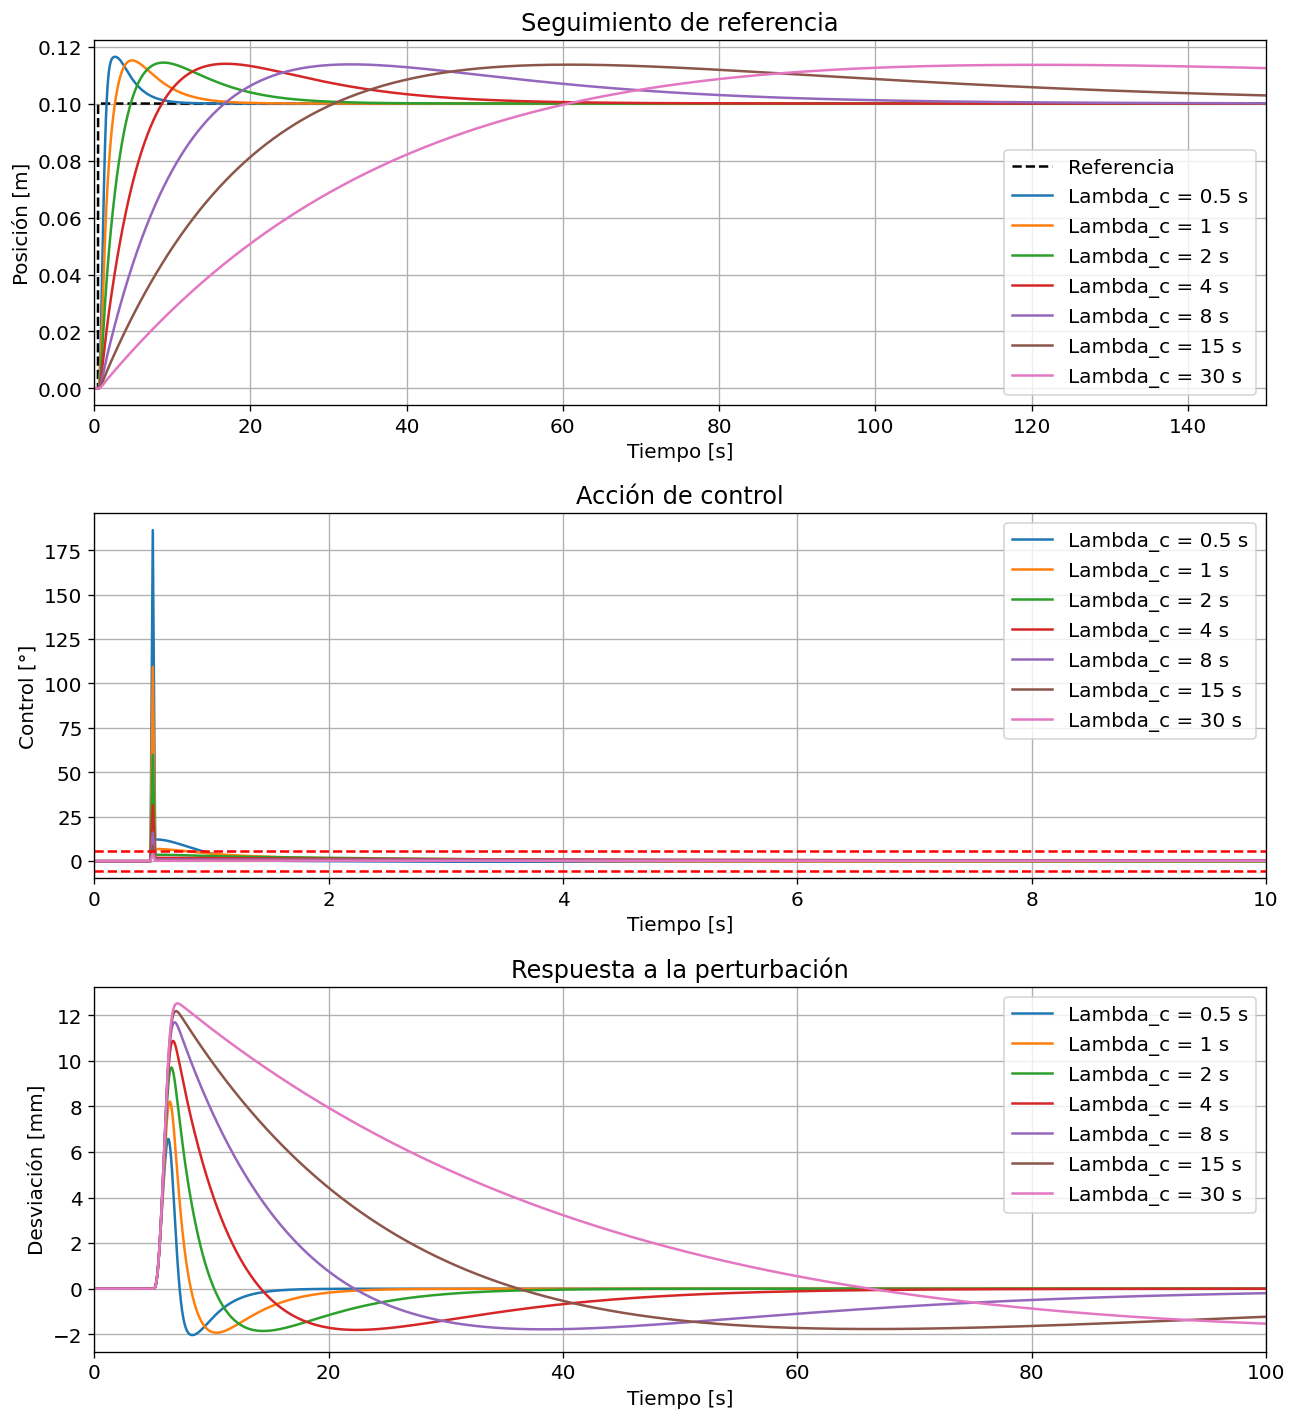

In [ ]:
#Comparación de las respuestas temporales
seleccion = [0.5, 1, 2, 4, 8, 15, 30]

fig, ax = plt.subplots(
    3, 1, figsize=(11, 12)
)

ax[0].plot(
    t_barrido, ref_barrido,
    "k--", label="Referencia"
)

for lc in seleccion:

    datos = senales_barrido[lc]

    if datos is None:
        continue

    etiqueta = f"Lambda_c = {lc} s"

    ax[0].plot(
        t_barrido, datos["y"],
        label=etiqueta
    )

    ax[1].plot(
        t_barrido,
        np.rad2deg(datos["u"]),
        label=etiqueta
    )

    ax[2].plot(
        t_barrido,
        1000*datos["yd"],
        label=etiqueta
    )

ax[0].set_ylabel("Posición [m]")
ax[0].set_title("Seguimiento de referencia")
ax[0].set_xlim(0, 150)

ax[1].set_ylabel("Control [°]")
ax[1].set_title("Acción de control")
ax[1].set_xlim(0, 10)

ax[1].axhline(
    5.6975, color="red", linestyle="--"
)

ax[1].axhline(
    -5.6975, color="red", linestyle="--"
)

ax[2].set_ylabel("Desviación [mm]")
ax[2].set_title("Respuesta a la perturbación")
ax[2].set_xlim(0, 100)

for a in ax:

    a.set_xlabel("Tiempo [s]")
    a.grid(True)
    a.legend()

plt.tight_layout()
plt.show()

In [ ]:
#Selección del mejor candidato
u_referencia = 5.6975

candidatos = tabla_simc[
    (tabla_simc["Estable"]) &
    (tabla_simc["Establecimiento [s]"].notna()) &
    (tabla_simc["Control máximo [°]"] <= u_referencia) &
    (
        tabla_simc["Control máximo con perturbación [°]"]
        <= u_referencia
    )
].copy()

if candidatos.empty:

    print(
        "Ningún candidato cumple todos los criterios."
    )

else:

    mejor_simc = candidatos.sort_values(
        "Establecimiento [s]"
    ).iloc[0]

    print("MEJOR CANDIDATO SIMC-PID")

    display(mejor_simc.to_frame().round(6))

Ningún candidato cumple todos los criterios.


In [ ]:
#Función de evaluación del SIMC-PID 2DOF
def evaluar_simc_2dof(
    lambda_c, br, cr, planta, t, ref, du
):

    Kc, Ti, Td, Kp, Ki, Kd = sintonizar_simc(
        Kv, tau_ret, L_ret, lambda_c
    )

    kp = Kp
    ki = Ki*Ts/Kp
    kd = Kd/(Kp*Ts)

    # Modelo discreto de la planta
    P = ct.ss(planta)

    Ap = np.asarray(P.A)
    Bp = np.asarray(P.B)
    Cp = np.asarray(P.C)
    Dp = np.asarray(P.D)

    if not np.allclose(Dp, 0):
        raise ValueError(
            "Se requiere una planta estrictamente propia."
        )

    # Estados del controlador:
    # xc[0]: integral acumulada
    # xc[1]: error derivativo anterior

    Ac = np.array([
        [1, 0],
        [0, 0]
    ])

    Bcr = np.array([
        [Ts],
        [cr]
    ])

    Bcy = np.array([
        [-Ts],
        [-1]
    ])

    Cc = np.array([
        [Ki, -Kd/Ts]
    ])

    Dcr = Kp*br + Ki*Ts + Kd*cr/Ts
    Dcy = -Kp - Ki*Ts - Kd/Ts

    # Realización conjunta del lazo cerrado

    Acl = np.block([
        [Ap + Bp*Dcy@Cp, Bp@Cc],
        [Bcy@Cp, Ac]
    ])

    Br = np.vstack([
        Bp*Dcr,
        Bcr
    ])

    Bd = np.vstack([
        Bp,
        np.zeros((2, 1))
    ])

    Cy = np.hstack([
        Cp,
        np.zeros((1, 2))
    ])

    Cu = np.hstack([
        Dcy*Cp,
        Cc
    ])

    Bcl = np.hstack([Br, Bd])

    Ccl = np.vstack([Cy, Cu])

    Dcl = np.array([
        [0, 0],
        [Dcr, 0]
    ])

    sistema = ct.ss(
        Acl, Bcl, Ccl, Dcl, Ts
    )

    polos = np.linalg.eigvals(Acl)
    rho = np.max(np.abs(polos))

    resultado = {
        "Lambda_c [s]": lambda_c,
        "br": br,
        "cr": cr,
        "kp": kp,
        "ki": ki,
        "kd": kd,
        "Radio espectral": rho,
        "Estable": rho < 1
    }

    if rho >= 1:
        return resultado, None

    # Ensayo de seguimiento
    _, salida_ref = ct.forced_response(
        sistema,
        t,
        np.vstack([
            ref,
            np.zeros_like(t)
        ])
    )

    y, u = salida_ref

    # Ensayo de perturbación
    _, salida_pert = ct.forced_response(
        sistema,
        t,
        np.vstack([
            np.zeros_like(t),
            du
        ])
    )

    yd, ud = salida_pert

    y_total = y + yd
    u_total = u + ud

    resultado.update(
        indicadores_control(
            t, ref, y, u, yd, u_total
        )
    )

    senales = {
        "y": y,
        "u": u,
        "yd": yd,
        "ud": ud,
        "y_total": y_total,
        "u_total": u_total,
        "polos": polos,
        "sistema": sistema
    }

    return resultado, senales

In [ ]:
#Comparación de estructuras
t_2dof = np.arange(0, 60 + Ts/2, Ts)

ref_2dof = 0.1*(t_2dof >= 0.5)

du_2dof = np.deg2rad(1)*(
    (t_2dof >= 5) &
    (t_2dof < 6)
)

configuraciones = [
    ("PID convencional", 1, 1),
    ("PI-D", 1, 0),
    ("PID ponderado 0.8", 0.8, 0),
    ("PID ponderado 0.6", 0.6, 0),
    ("PID ponderado 0.4", 0.4, 0),
    ("PID ponderado 0.2", 0.2, 0),
    ("I-PD", 0, 0)
]

resultados_2dof = []
senales_2dof = {}

for nombre, br, cr in configuraciones:

    resultado, senales = evaluar_simc_2dof(
        0.5, br, cr,
        Gd,
        t_2dof,
        ref_2dof,
        du_2dof
    )

    resultado["Configuración"] = nombre

    resultados_2dof.append(resultado)

    senales_2dof[nombre] = senales

tabla_2dof = pd.DataFrame(
    resultados_2dof
).set_index("Configuración")

display(tabla_2dof.round(6))

,Lambda_c [s],br,cr,kp,ki,kd,Radio espectral,Estable,Sobreimpulso [%],Establecimiento [s],Control máximo [°],Control máximo con perturbación [°],Control RMS [°],RMSE referencia [m],Error final [m],Desviación por perturbación [mm]
Configuración,,,,,,,,,,,,,,,,
PID convencional,0.5,1.0,1,2.094154,0.006284,14.522834,0.989474,True,16.414427993680118,7.32,186.32797363022632,186.32797363022632,3.5072591069836334,0.009380410058589592,0.0,6.57554793090849
PI-D,0.5,1.0,0,2.094154,0.006284,14.522834,0.989474,True,23.120882801870273,8.24,12.384063829848909,12.384063829848909,1.209277339312968,0.011473462792002667,-0.0,6.57554793090849
PID ponderado 0.8,0.5,0.8,0,2.094154,0.006284,14.522834,0.989474,True,8.888936007113823,6.92,10.023372754964715,10.023372754964715,1.0023539688522232,0.011241202662168708,0.0,6.57554793090849
PID ponderado 0.6,0.5,0.6,0,2.094154,0.006284,14.522834,0.989474,True,0.04968819706238636,3.52,7.681108727912791,7.681108727912791,0.8052445832369792,0.012072364722737785,0.0,6.57554793090849
PID ponderado 0.4,0.5,0.4,0,2.094154,0.006284,14.522834,0.989474,True,5.939693181744587e-10,6.82,5.389620768827247,5.389620768827247,0.6272700879635899,0.013775790596560842,0.0,6.57554793090849
PID ponderado 0.2,0.5,0.2,0,2.094154,0.006284,14.522834,0.989474,True,6.178391132038996e-10,8.16,3.2653030989346816,3.2653030989346816,0.4897552982231661,0.016076563282505157,0.0,6.57554793090849
I-PD,0.5,0.0,0,2.094154,0.006284,14.522834,0.989474,True,4.6387893526400603e-10,8.94,2.2709039006245204,2.2709039006245204,0.43312389161184006,0.018756130497713738,-0.0,6.57554793090849


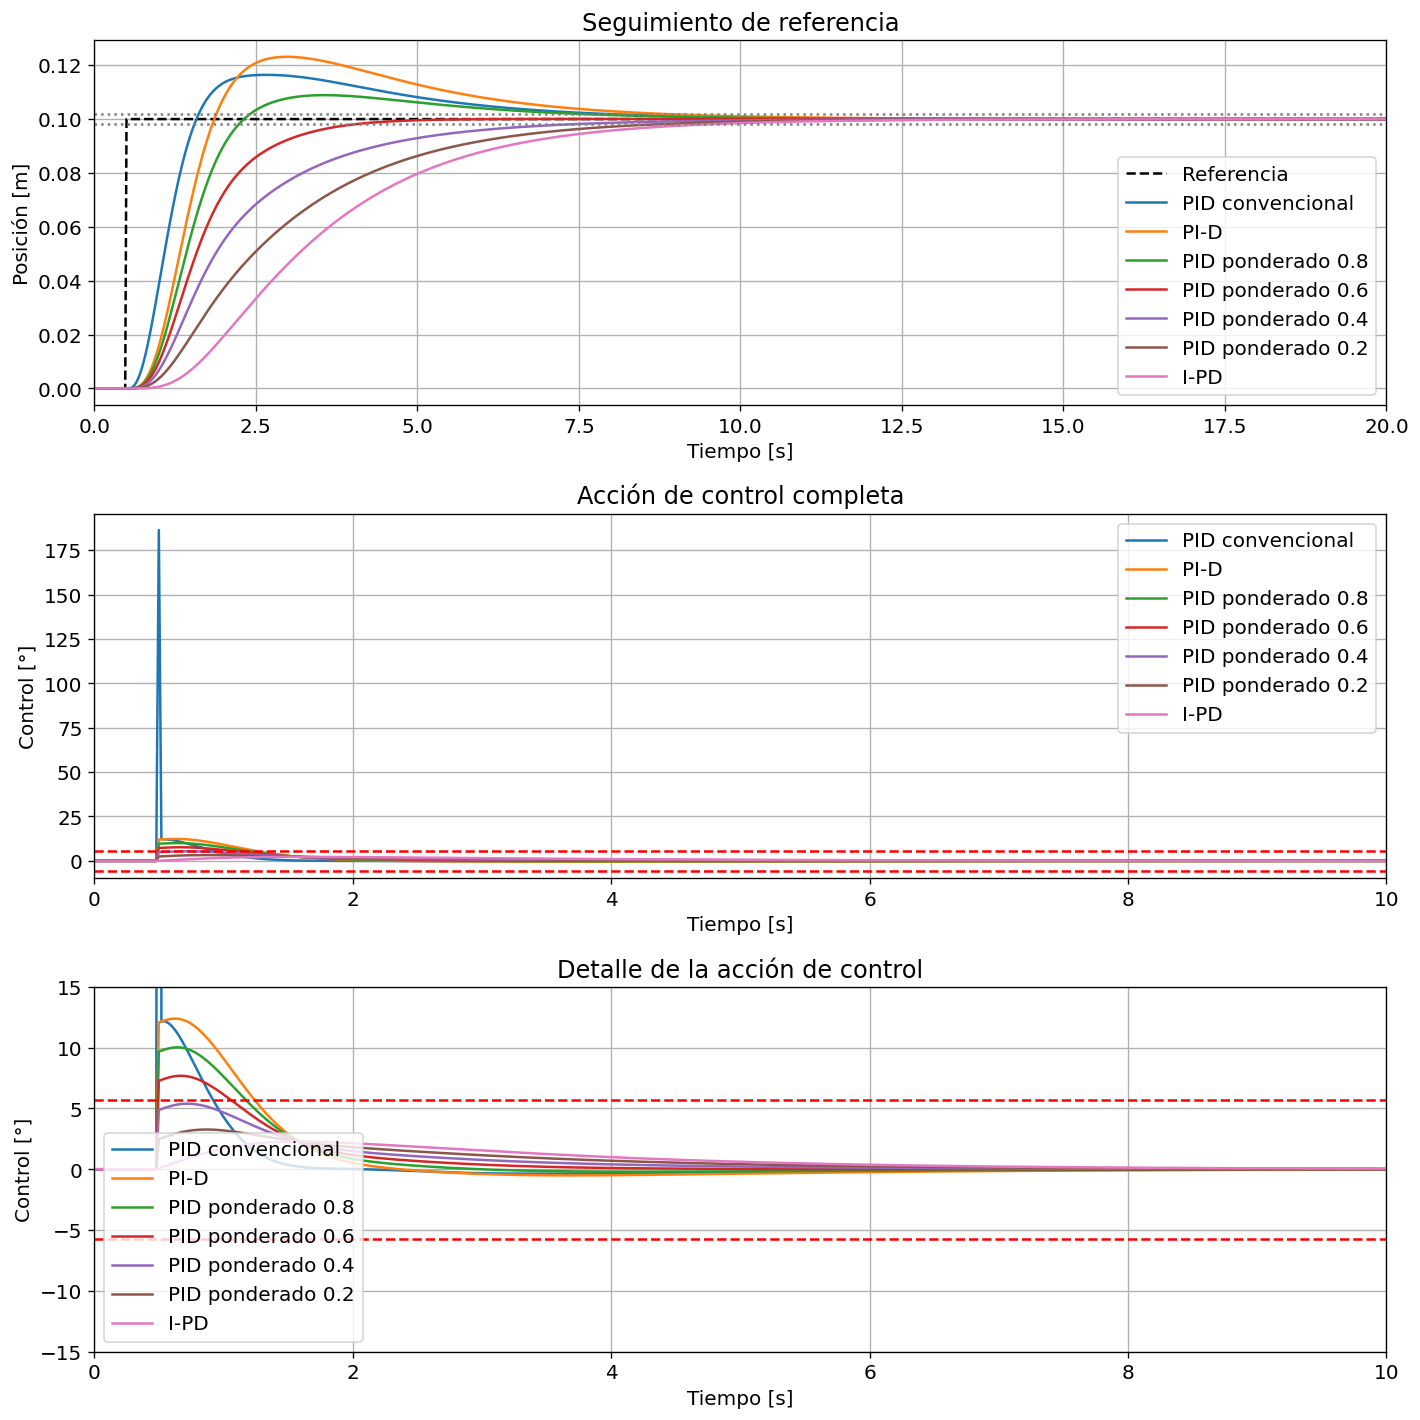

In [ ]:
#Comparación gráfica
fig, ax = plt.subplots(
    3, 1, figsize=(12, 12)
)

ax[0].plot(
    t_2dof, ref_2dof,
    "k--", label="Referencia"
)

for nombre, datos in senales_2dof.items():

    if datos is None:
        continue

    ax[0].plot(
        t_2dof, datos["y"],
        label=nombre
    )

    ax[1].plot(
        t_2dof,
        np.rad2deg(datos["u"]),
        label=nombre
    )

    ax[2].plot(
        t_2dof,
        np.rad2deg(datos["u"]),
        label=nombre
    )

ax[0].axhline(
    0.102, color="gray", linestyle=":"
)

ax[0].axhline(
    0.098, color="gray", linestyle=":"
)

ax[0].set_title("Seguimiento de referencia")
ax[0].set_ylabel("Posición [m]")
ax[0].set_xlim(0, 20)

ax[1].set_title("Acción de control completa")
ax[1].set_ylabel("Control [°]")
ax[1].set_xlim(0, 10)

ax[2].set_title("Detalle de la acción de control")
ax[2].set_ylabel("Control [°]")
ax[2].set_xlim(0, 10)
ax[2].set_ylim(-15, 15)

for a in ax[1:]:

    a.axhline(
        5.6975, color="red", linestyle="--"
    )

    a.axhline(
        -5.6975, color="red", linestyle="--"
    )

for a in ax:

    a.set_xlabel("Tiempo [s]")
    a.grid(True)
    a.legend()

plt.tight_layout()

plt.savefig(
    "comparacion_SIMC_2DOF.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

VERIFICACIÓN DE EQUIVALENCIA
PID convencional         : diferencia = 0.000e+00 m
PI-D                     : diferencia = 0.000e+00 m
PID ponderado 0.8        : diferencia = 0.000e+00 m
PID ponderado 0.6        : diferencia = 0.000e+00 m
PID ponderado 0.4        : diferencia = 0.000e+00 m
PID ponderado 0.2        : diferencia = 0.000e+00 m
I-PD                     : diferencia = 0.000e+00 m


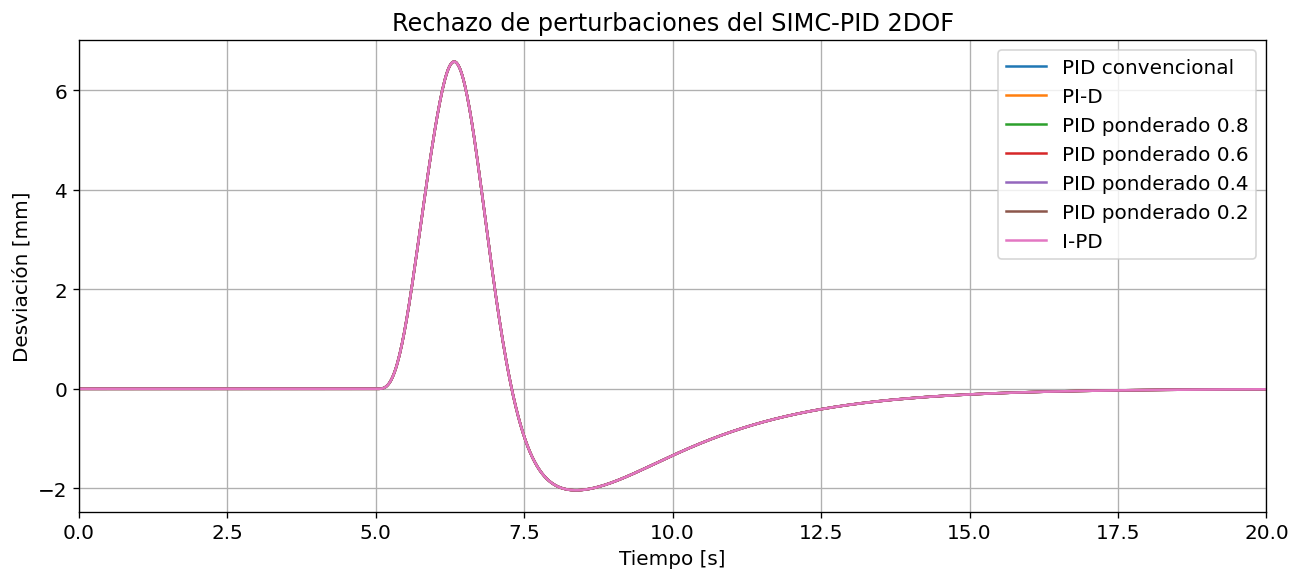

In [ ]:
#Verificación del rechazo de perturbaciones
base = senales_2dof["PID convencional"]

print("VERIFICACIÓN DE EQUIVALENCIA")

for nombre, datos in senales_2dof.items():

    if datos is None:
        continue

    diferencia = np.max(
        np.abs(datos["yd"] - base["yd"])
    )

    print(
        f"{nombre:25s}: "
        f"diferencia = {diferencia:.3e} m"
    )

plt.figure(figsize=(11, 5))

for nombre, datos in senales_2dof.items():

    if datos is None:
        continue

    plt.plot(
        t_2dof,
        1000*datos["yd"],
        label=nombre
    )

plt.xlabel("Tiempo [s]")
plt.ylabel("Desviación [mm]")
plt.title("Rechazo de perturbaciones del SIMC-PID 2DOF")
plt.xlim(0, 20)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#Barrido conjunto de parámetros
lambda_2dof = np.array([
    0.25, 0.35, 0.50, 0.60,
    0.75, 1.00, 1.25, 1.50,
    2.00, 3.00, 4.00, 6.00
])

br_2dof = np.linspace(0, 1, 21)

cr_fijo = 0

t_barrido_2dof = np.arange(
    0, 120 + Ts/2, Ts
)

ref_barrido_2dof = 0.1*(
    t_barrido_2dof >= 0.5
)

du_barrido_2dof = np.deg2rad(1)*(
    (t_barrido_2dof >= 5) &
    (t_barrido_2dof < 6)
)

resultados_barrido_2dof = []

for lc in lambda_2dof:

    for br in br_2dof:

        resultado, _ = evaluar_simc_2dof(
            lc,
            br,
            cr_fijo,
            Gd,
            t_barrido_2dof,
            ref_barrido_2dof,
            du_barrido_2dof
        )

        resultados_barrido_2dof.append(
            resultado
        )

tabla_barrido_2dof = pd.DataFrame(
    resultados_barrido_2dof
)

print(
    "Configuraciones evaluadas:",
    len(tabla_barrido_2dof)
)

print(
    "Configuraciones estables:",
    tabla_barrido_2dof["Estable"].sum()
)

display(tabla_barrido_2dof.round(6))

Configuraciones evaluadas: 252
Configuraciones estables: 252


,Lambda_c [s],br,cr,kp,ki,kd,Radio espectral,Estable,Sobreimpulso [%],Establecimiento [s],Control máximo [°],Control máximo con perturbación [°],Control RMS [°],RMSE referencia [m],Error final [m],Desviación por perturbación [mm]
0,0.25,0.00,0,3.396439,0.009163,13.770465,0.984538,True,5.279388037848776e-10,6.04,4.063848622918856,4.063848622918856,0.3941223567604221,0.011095754474846094,0.000000,5.091023035812005
1,0.25,0.05,0,3.396439,0.009163,13.770465,0.984538,True,4.967415367929107e-10,5.94,4.181712283339858,4.181712283339858,0.39934125222148475,0.010693837405338275,-0.000000,5.091023035812005
2,0.25,0.10,0,3.396439,0.009163,13.770465,0.984538,True,5.275502257262588e-10,5.80,4.529519274914943,4.529519274914943,0.413054104624754,0.0103037203355834,0.000000,5.091023035812005
3,0.25,0.15,0,3.396439,0.009163,13.770465,0.984538,True,6.000616670220893e-10,5.66,5.082651224123547,5.082651224123547,0.4344573684034268,0.009926794561799058,-0.000000,5.091023035812005
4,0.25,0.20,0,3.396439,0.009163,13.770465,0.984538,True,6.038503030936226e-10,5.52,5.7724011431159274,5.7724011431159274,0.4624845625173975,0.009564619752336105,0.000000,5.091023035812005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,6.00,0.80,0,0.219212,0.000794,15.957405,0.998568,True,4.619312292802713,55.52,1.0107363699852956,1.0107363699852956,0.1930600882058125,0.018168238601624295,-0.000034,11.400241600547895
248,6.00,0.85,0,0.219212,0.000794,15.957405,0.998568,True,6.769254374050903,59.66,1.0733546632596214,1.0733546632596214,0.2019466056447408,0.01770678599835505,-0.000041,11.400241600547895
249,6.00,0.90,0,0.219212,0.000794,15.957405,0.998568,True,9.17227464993922,62.80,1.1360240354239863,1.1360240354239863,0.21096280333267156,0.017387579813339746,-0.000048,11.400241600547895
250,6.00,0.95,0,0.219212,0.000794,15.957405,0.998568,True,11.776235975789195,65.32,1.1986934075883515,1.1986934075883515,0.22009274461583817,0.017218532980356107,-0.000055,11.400241600547895


In [ ]:
def convertir_escalar(valor):

    if isinstance(valor, (str, bool, np.bool_)):
        return valor

    arr = np.asarray(valor)

    if arr.size == 1:
        return arr.item()

    raise ValueError(
        f"Se esperaba un escalar. "
        f"Dimensiones obtenidas: {arr.shape}"
    )


def limpiar_tabla(tabla):

    tabla_limpia = tabla.copy()

    for columna in tabla_limpia.columns:

        tabla_limpia[columna] = (
            tabla_limpia[columna]
            .map(convertir_escalar)
        )

    return tabla_limpia

print("Funciones auxiliares cargadas correctamente.")
tabla_barrido_2dof = limpiar_tabla(
    tabla_barrido_2dof
)

print(tabla_barrido_2dof.dtypes)

Funciones auxiliares cargadas correctamente.
Lambda_c [s]                           float64
br                                     float64
cr                                       int64
kp                                     float64
ki                                     float64
kd                                     float64
Radio espectral                        float64
Estable                                   bool
Sobreimpulso [%]                       float64
Establecimiento [s]                    float64
Control máximo [°]                     float64
Control máximo con perturbación [°]    float64
Control RMS [°]                        float64
RMSE referencia [m]                    float64
Error final [m]                        float64
Desviación por perturbación [mm]       float64
dtype: object


In [ ]:
#Selección de candidatos
u_ref_ift = 5.6975

candidatos_2dof = tabla_barrido_2dof[
    (tabla_barrido_2dof["Estable"]) &

    (tabla_barrido_2dof[
        "Control máximo [°]"
    ] <= u_ref_ift) &

    (tabla_barrido_2dof[
        "Control máximo con perturbación [°]"
    ] <= u_ref_ift) &

    (np.isfinite(
        tabla_barrido_2dof[
            "Establecimiento [s]"
        ]
    ))
].copy()

candidatos_2dof = candidatos_2dof.sort_values(
    by=[
        "Establecimiento [s]",
        "Sobreimpulso [%]",
        "Desviación por perturbación [mm]"
    ]
)

print(
    "Candidatos admisibles:",
    len(candidatos_2dof)
)

if not candidatos_2dof.empty:

    print("\nMEJORES 15 CONFIGURACIONES")

    display(
        candidatos_2dof.head(15).round(6)
    )

    mejor_2dof = candidatos_2dof.iloc[0]

    print("\nMEJOR CONFIGURACIÓN")

    display(mejor_2dof.to_frame("SIMC-PID 2DOF"))

else:

    print(
        "Ningún candidato cumple los criterios."
    )

Candidatos admisibles: 186

MEJORES 15 CONFIGURACIONES


,Lambda_c [s],br,cr,kp,ki,kd,Radio espectral,Estable,Sobreimpulso [%],Establecimiento [s],Control máximo [°],Control máximo con perturbación [°],Control RMS [°],RMSE referencia [m],Error final [m],Desviación por perturbación [mm]
96,0.75,0.60,0,1.510686,0.004782,14.915439,0.991963,True,0.030687,5.00,5.463521,5.463521,0.460809,0.009501,0.0,7.536677
118,1.00,0.65,0,1.180713,0.003859,15.156535,0.993477,True,0.755260,5.20,4.562798,4.562798,0.419020,0.010041,-0.0,8.214550
3,0.25,0.15,0,3.396439,0.009163,13.770465,0.984538,True,0.000000,5.66,5.082651,5.082651,0.434457,0.009927,-0.0,5.091023
2,0.25,0.10,0,3.396439,0.009163,13.770465,0.984538,True,0.000000,5.80,4.529519,4.529519,0.413054,0.010304,0.0,5.091023
1,0.25,0.05,0,3.396439,0.009163,13.770465,0.984538,True,0.000000,5.94,4.181712,4.181712,0.399341,0.010694,-0.0,5.091023
0,0.25,0.00,0,3.396439,0.009163,13.770465,0.984538,True,0.000000,6.04,4.063849,4.063849,0.394122,0.011096,0.0,5.091023
95,0.75,0.55,0,1.510686,0.004782,14.915439,0.991963,True,0.000000,6.30,5.042451,5.042451,0.435130,0.009818,-0.0,7.536677
73,0.60,0.50,0,1.814242,0.005583,14.706177,0.990642,True,0.000000,6.32,5.607076,5.607076,0.459536,0.009530,-0.0,7.004653
161,1.50,0.70,0,0.821231,0.002785,15.437325,0.995238,True,1.896560,6.34,3.375095,3.375095,0.357316,0.011129,-0.0,9.122199
26,0.35,0.25,0,2.721803,0.007744,14.141330,0.987005,True,0.000000,6.36,5.074746,5.074746,0.429099,0.009943,-0.0,5.772432



MEJOR CONFIGURACIÓN


,SIMC-PID 2DOF
Lambda_c [s],0.75
br,0.6
cr,0
kp,1.510686
ki,0.004782
kd,14.915439
Radio espectral,0.991963
Estable,True
Sobreimpulso [%],0.030687
Establecimiento [s],5.0


In [ ]:
# ==========================================================
# CORRECCIÓN DE TIPOS DE DATOS DEL BARRIDO SIMC-PID 2DOF
# ==========================================================

def convertir_escalar(valor):

    if isinstance(valor, (str, bool, np.bool_)):
        return valor

    arr = np.asarray(valor)

    if arr.size == 1:
        return arr.item()

    raise ValueError(
        f"Se esperaba un escalar, se obtuvo {arr.shape}"
    )


resultados_limpios_2dof = [
    {
        clave: convertir_escalar(valor)
        for clave, valor in resultado.items()
    }
    for resultado in resultados_barrido_2dof
]

tabla_barrido_2dof = pd.DataFrame(
    resultados_limpios_2dof
)

# Asegurar los tipos de datos de cada columna

for columna in tabla_barrido_2dof.columns:

    if columna == "Estable":
        tabla_barrido_2dof[columna] = (
            tabla_barrido_2dof[columna].astype(bool)
        )

    else:
        tabla_barrido_2dof[columna] = pd.to_numeric(
            tabla_barrido_2dof[columna],
            errors="raise"
        )

print("Corrección de tipos completada.")

print(
    "Configuraciones evaluadas:",
    len(tabla_barrido_2dof)
)

print(
    "Configuraciones estables:",
    tabla_barrido_2dof["Estable"].sum()
)

print("\nTipos de datos:")
print(tabla_barrido_2dof.dtypes)

display(tabla_barrido_2dof.head().round(6))

Corrección de tipos completada.
Configuraciones evaluadas: 252
Configuraciones estables: 252

Tipos de datos:
Lambda_c [s]                           float64
br                                     float64
cr                                       int64
kp                                     float64
ki                                     float64
kd                                     float64
Radio espectral                        float64
Estable                                   bool
Sobreimpulso [%]                       float64
Establecimiento [s]                    float64
Control máximo [°]                     float64
Control máximo con perturbación [°]    float64
Control RMS [°]                        float64
RMSE referencia [m]                    float64
Error final [m]                        float64
Desviación por perturbación [mm]       float64
dtype: object


,Lambda_c [s],br,cr,kp,ki,kd,Radio espectral,Estable,Sobreimpulso [%],Establecimiento [s],Control máximo [°],Control máximo con perturbación [°],Control RMS [°],RMSE referencia [m],Error final [m],Desviación por perturbación [mm]
0,0.25,0.00,0,3.396439,0.009163,13.770465,0.984538,True,0.0,6.04,4.063849,4.063849,0.394122,0.011096,0.0,5.091023
1,0.25,0.05,0,3.396439,0.009163,13.770465,0.984538,True,0.0,5.94,4.181712,4.181712,0.399341,0.010694,-0.0,5.091023
2,0.25,0.10,0,3.396439,0.009163,13.770465,0.984538,True,0.0,5.80,4.529519,4.529519,0.413054,0.010304,0.0,5.091023
3,0.25,0.15,0,3.396439,0.009163,13.770465,0.984538,True,0.0,5.66,5.082651,5.082651,0.434457,0.009927,-0.0,5.091023
4,0.25,0.20,0,3.396439,0.009163,13.770465,0.984538,True,0.0,5.52,5.772401,5.772401,0.462485,0.009565,0.0,5.091023


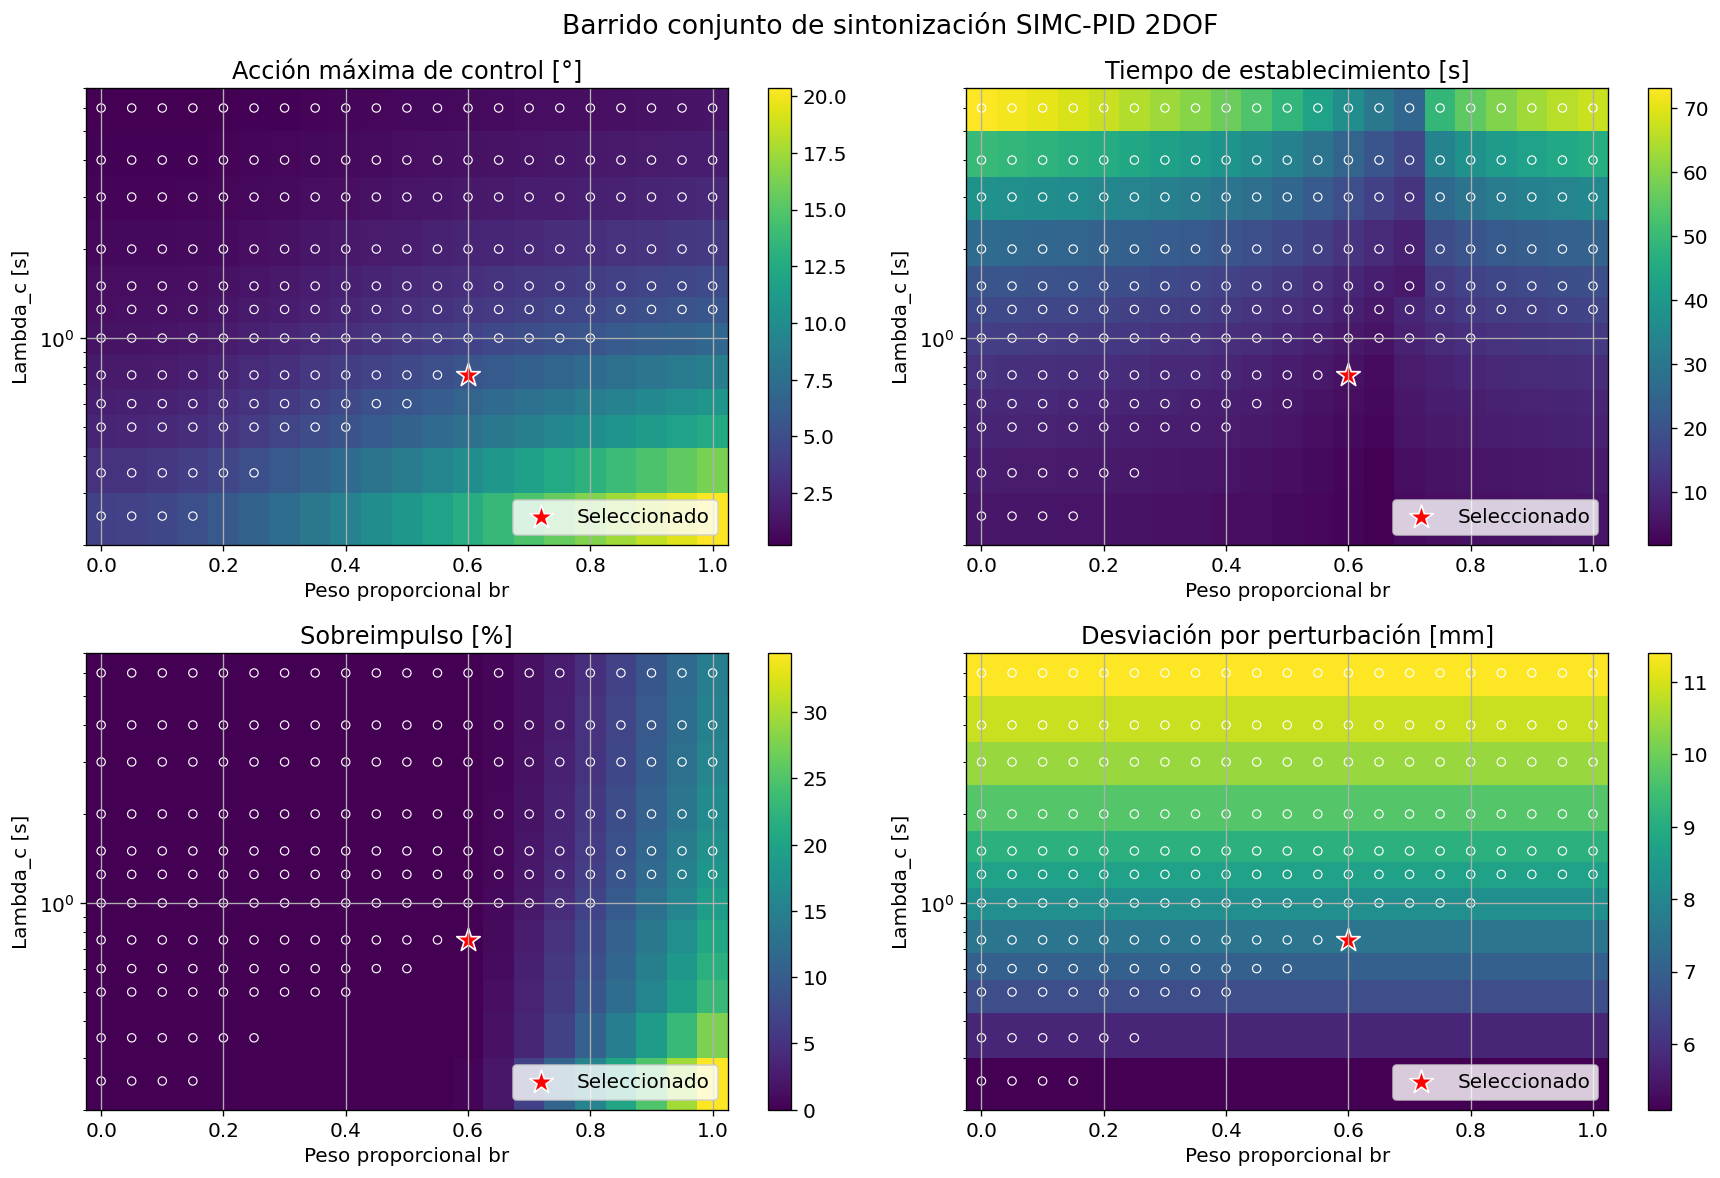

In [ ]:
#Mapas de desempeño
fig, ax = plt.subplots(
    2, 2, figsize=(15, 10)
)

metricas = [
    ("Control máximo [°]",
     "Acción máxima de control [°]"),

    ("Establecimiento [s]",
     "Tiempo de establecimiento [s]"),

    ("Sobreimpulso [%]",
     "Sobreimpulso [%]"),

    ("Desviación por perturbación [mm]",
     "Desviación por perturbación [mm]")
]

for a, (metrica, titulo) in zip(
    ax.flat, metricas
):

    matriz = tabla_barrido_2dof.pivot(
        index="Lambda_c [s]",
        columns="br",
        values=metrica
    )

    X, Y = np.meshgrid(
        matriz.columns,
        matriz.index
    )

    Z = np.ma.masked_invalid(
        matriz.to_numpy(dtype=float)
    )

    mapa = a.pcolormesh(
        X, Y, Z,
        shading="auto",
        cmap="viridis"
    )

    fig.colorbar(mapa, ax=a)

    if not candidatos_2dof.empty:

        a.scatter(
            candidatos_2dof["br"],
            candidatos_2dof["Lambda_c [s]"],
            facecolors="none",
            edgecolors="white",
            s=25,
            linewidths=0.7
        )

        a.scatter(
            mejor_2dof["br"],
            mejor_2dof["Lambda_c [s]"],
            marker="*",
            color="red",
            edgecolor="white",
            s=220,
            label="Seleccionado"
        )

        a.legend()

    a.set_title(titulo)
    a.set_xlabel("Peso proporcional br")
    a.set_ylabel("Lambda_c [s]")
    a.set_yscale("log")

fig.suptitle(
    "Barrido conjunto de sintonización SIMC-PID 2DOF",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "barrido_conjunto_SIMC_2DOF.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Validación individual del SIMC-PID 2DOF seleccionado
# Validación individual del SIMC-PID 2DOF seleccionado

lambda_final = float(mejor_2dof["Lambda_c [s]"])
br_final = float(mejor_2dof["br"])
cr_final = float(mejor_2dof["cr"])

# Condiciones comunes de validación

t_final = np.arange(0, 60 + Ts/2, Ts)

ref_final = 0.1*(t_final >= 0.5)

du_final = np.deg2rad(1)*(
    (t_final >= 5) &
    (t_final < 6)
)

# Evaluación sobre el modelo nominal completo

resultado_final, senales_final = evaluar_simc_2dof(
    lambda_final,
    br_final,
    cr_final,
    Gd,
    t_final,
    ref_final,
    du_final
)

if senales_final is None:
    raise RuntimeError(
        "El controlador seleccionado no es estable."
    )

resultado_final = {
    clave: convertir_escalar(valor)
    for clave, valor in resultado_final.items()
}

# Conversión de las señales a arrays de NumPy

senales_final = {
    clave: np.asarray(valor).squeeze()
    if clave != "sistema" else valor
    for clave, valor in senales_final.items()
}

print("="*60)
print("VALIDACIÓN FINAL DEL SIMC-PID 2DOF")
print("="*60)

print(f"Lambda_c = {lambda_final:.6f} s")
print(f"br       = {br_final:.6f}")
print(f"cr       = {cr_final:.6f}")
print(f"Ts       = {Ts:.6f} s")

print("\nGANANCIAS DEL CONTROLADOR")

Kc_final, Ti_final, Td_final, \
Kp_final, Ki_final, Kd_final = sintonizar_simc(
    Kv, tau_ret, L_ret, lambda_final
)

print(f"Kc = {Kc_final:.8f}")
print(f"Ti = {Ti_final:.8f} s")
print(f"Td = {Td_final:.8f} s")

print("\nForma paralela:")
print(f"Kp = {Kp_final:.8f}")
print(f"Ki = {Ki_final:.8f}")
print(f"Kd = {Kd_final:.8f}")

print("\nForma discreta:")
print(f"kp = {resultado_final['kp']:.8f}")
print(f"ki = {resultado_final['ki']:.8f}")
print(f"kd = {resultado_final['kd']:.8f}")

print("\nINDICADORES DE DESEMPEÑO")

tabla_final_simc = pd.DataFrame(
    resultado_final,
    index=["SIMC-PID 2DOF"]
).T

display(tabla_final_simc)

print("\nPOLOS DEL LAZO CERRADO")

for p in senales_final["polos"]:
    print(
        f"{p.real:+.8f} "
        f"{p.imag:+.8f}j "
        f"|z| = {abs(p):.8f}"
    )

VALIDACIÓN FINAL DEL SIMC-PID 2DOF
Lambda_c = 0.750000 s
br       = 0.600000
cr       = 0.000000
Ts       = 0.020000 s

GANANCIAS DEL CONTROLADOR
Kc = 1.39391477
Ti = 3.85927352 s
Td = 0.32329867 s

Forma paralela:
Kp = 1.51068565
Ki = 0.36118579
Kd = 0.45065080

Forma discreta:
kp = 1.51068565
ki = 0.00478175
kd = 14.91543908

INDICADORES DE DESEMPEÑO


,SIMC-PID 2DOF
Lambda_c [s],0.75
br,0.6
cr,0.0
kp,1.510686
ki,0.004782
kd,14.915439
Radio espectral,0.991963
Estable,True
Sobreimpulso [%],0.030687
Establecimiento [s],5.0



POLOS DEL LAZO CERRADO
+0.00001783 +0.00000000j |z| = 0.00001783
+0.87053057 +0.00000000j |z| = 0.87053057
+0.93900001 +0.05351752j |z| = 0.94052387
+0.93900001 -0.05351752j |z| = 0.94052387
+0.98359991 +0.00000000j |z| = 0.98359991
+0.99196314 +0.00000000j |z| = 0.99196314


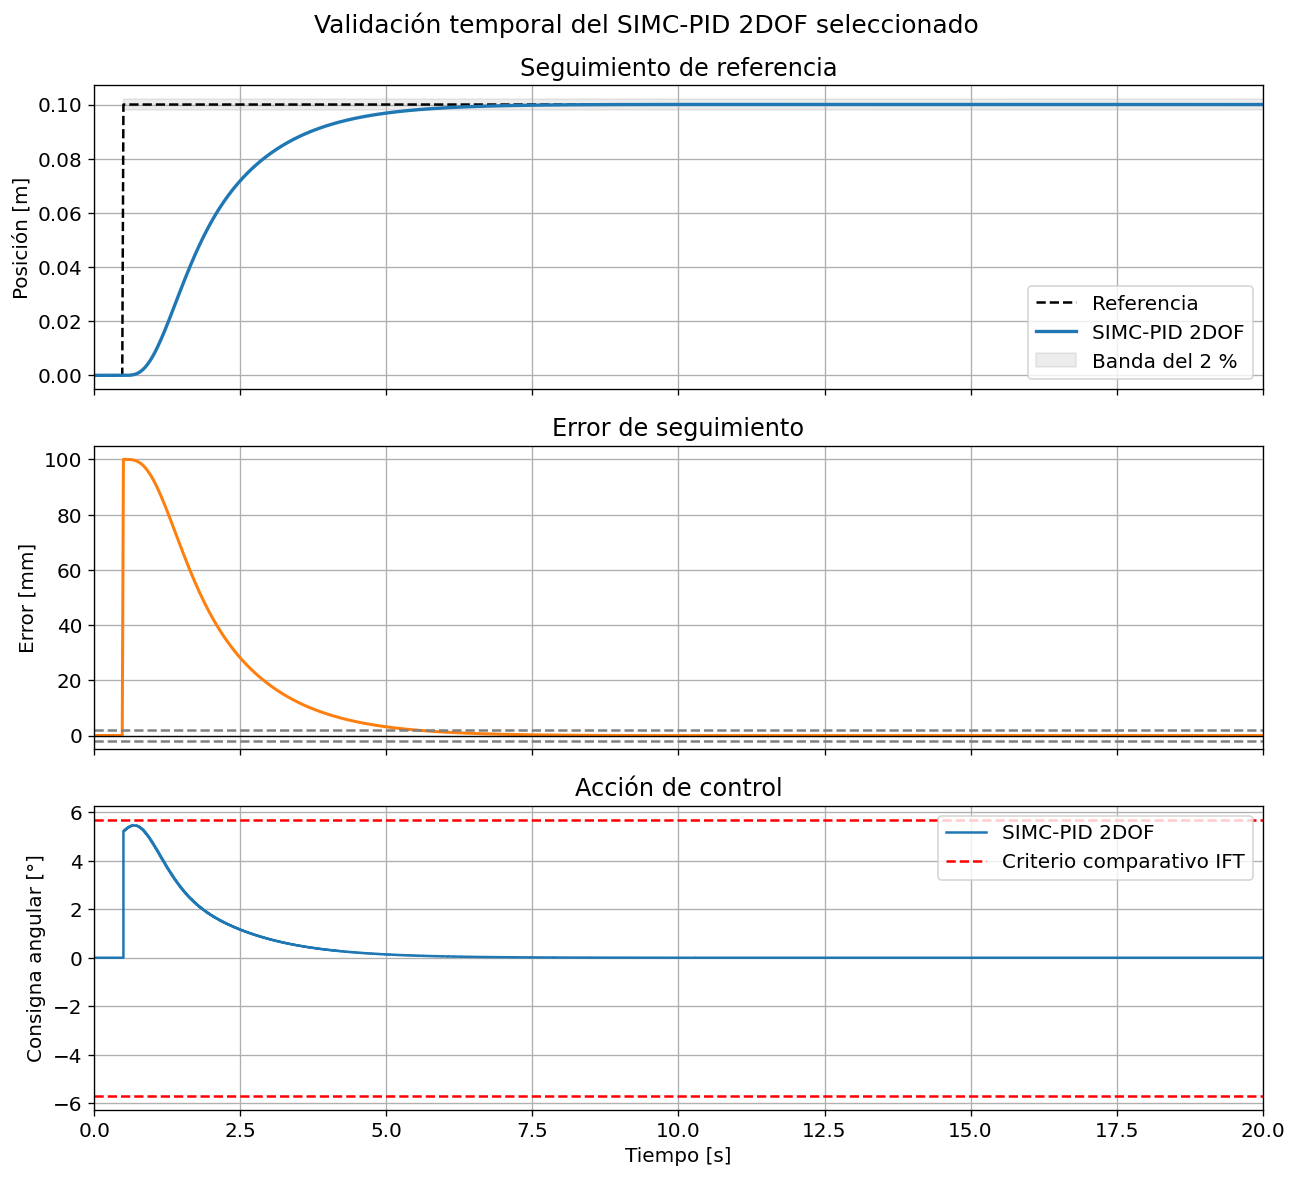

In [ ]:
#Seguimiento, error y acción de control
# Respuesta temporal del controlador seleccionado

y_final = senales_final["y"]
u_final = senales_final["u"]

e_final = ref_final - y_final

fig, ax = plt.subplots(
    3, 1,
    figsize=(11, 10),
    sharex=True
)

# 1. Seguimiento de referencia

ax[0].plot(
    t_final, ref_final,
    "k--",
    label="Referencia"
)

ax[0].plot(
    t_final, y_final,
    linewidth=2,
    label="SIMC-PID 2DOF"
)

ax[0].fill_between(
    t_final,
    ref_final - 0.002,
    ref_final + 0.002,
    where=t_final >= 0.5,
    color="gray",
    alpha=0.15,
    label="Banda del 2 %"
)

ax[0].set_ylabel("Posición [m]")
ax[0].set_title("Seguimiento de referencia")
ax[0].legend()
ax[0].grid(True)

# 2. Error de seguimiento

ax[1].plot(
    t_final,
    1000*e_final,
    linewidth=1.8,
    color="tab:orange"
)

ax[1].axhline(
    2, color="gray", linestyle="--"
)

ax[1].axhline(
    -2, color="gray", linestyle="--"
)

ax[1].axhline(
    0, color="black", linewidth=0.8
)

ax[1].set_ylabel("Error [mm]")
ax[1].set_title("Error de seguimiento")
ax[1].grid(True)

# 3. Acción de control

ax[2].step(
    t_final,
    np.rad2deg(u_final),
    where="post",
    linewidth=1.5,
    label="SIMC-PID 2DOF"
)

ax[2].axhline(
    u_ref_ift,
    color="red",
    linestyle="--",
    label="Criterio comparativo IFT"
)

ax[2].axhline(
    -u_ref_ift,
    color="red",
    linestyle="--"
)

ax[2].set_ylabel("Consigna angular [°]")
ax[2].set_xlabel("Tiempo [s]")
ax[2].set_title("Acción de control")
ax[2].legend()
ax[2].grid(True)

ax[2].set_xlim(0, 20)

fig.suptitle(
    "Validación temporal del SIMC-PID 2DOF seleccionado",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "simc_2dof_validacion_temporal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

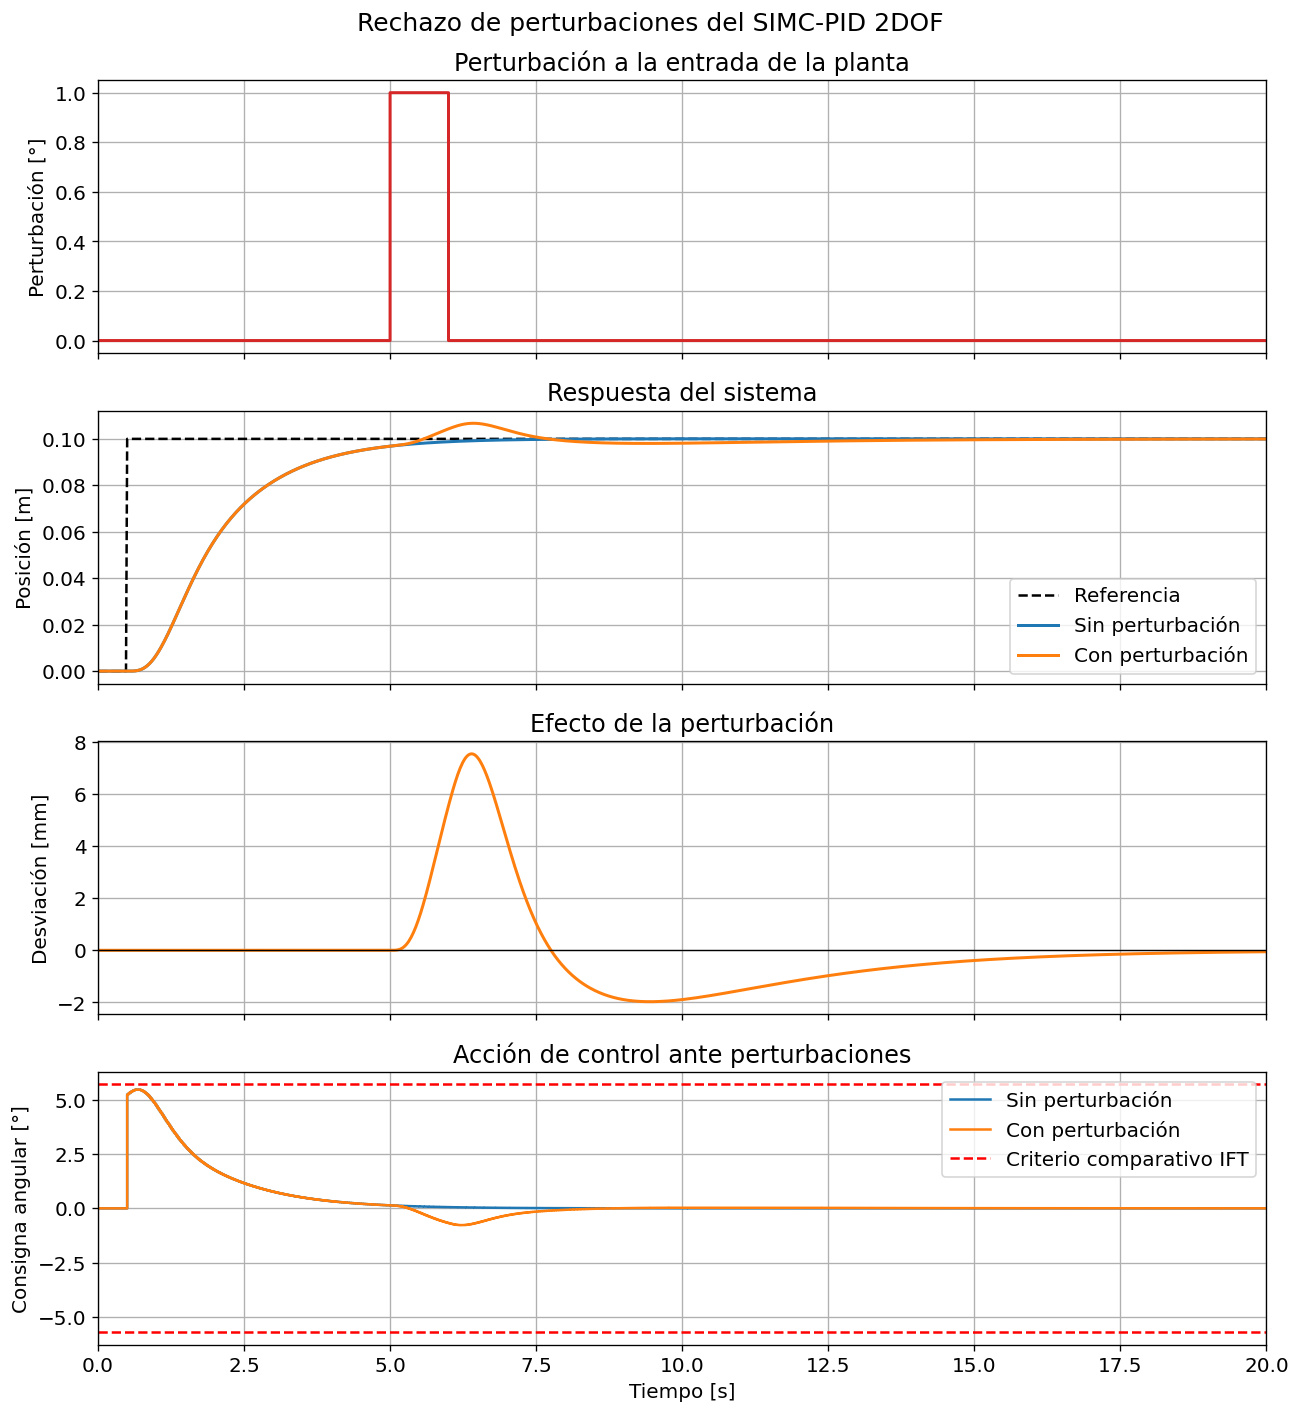

INDICADORES DE RECHAZO DE PERTURBACIONES
Desviación máxima: 7.536677 mm
Acción correctiva máxima: 0.817160°
Acción total máxima: 5.463521°


In [ ]:
#Validación frente a perturbaciones
# Validación del rechazo de perturbaciones

yd_final = senales_final["yd"]
ud_final = senales_final["ud"]

y_total_final = senales_final["y_total"]
u_total_final = senales_final["u_total"]

fig, ax = plt.subplots(
    4, 1,
    figsize=(11, 12),
    sharex=True
)

# 1. Perturbación aplicada

ax[0].step(
    t_final,
    np.rad2deg(du_final),
    where="post",
    color="tab:red",
    linewidth=1.8
)

ax[0].set_ylabel("Perturbación [°]")
ax[0].set_title("Perturbación a la entrada de la planta")
ax[0].grid(True)

# 2. Comparación de las respuestas

ax[1].plot(
    t_final, ref_final,
    "k--",
    label="Referencia"
)

ax[1].plot(
    t_final, y_final,
    linewidth=1.8,
    label="Sin perturbación"
)

ax[1].plot(
    t_final, y_total_final,
    linewidth=1.8,
    label="Con perturbación"
)

ax[1].set_ylabel("Posición [m]")
ax[1].set_title("Respuesta del sistema")
ax[1].legend()
ax[1].grid(True)

# 3. Desviación causada por la perturbación

ax[2].plot(
    t_final,
    1000*yd_final,
    color="tab:orange",
    linewidth=1.8
)

ax[2].axhline(
    0, color="black", linewidth=0.8
)

ax[2].set_ylabel("Desviación [mm]")
ax[2].set_title("Efecto de la perturbación")
ax[2].grid(True)

# 4. Acción de control

ax[3].step(
    t_final,
    np.rad2deg(u_final),
    where="post",
    label="Sin perturbación"
)

ax[3].step(
    t_final,
    np.rad2deg(u_total_final),
    where="post",
    label="Con perturbación"
)

ax[3].axhline(
    u_ref_ift,
    color="red",
    linestyle="--",
    label="Criterio comparativo IFT"
)

ax[3].axhline(
    -u_ref_ift,
    color="red",
    linestyle="--"
)

ax[3].set_ylabel("Consigna angular [°]")
ax[3].set_xlabel("Tiempo [s]")
ax[3].set_title("Acción de control ante perturbaciones")
ax[3].legend()
ax[3].grid(True)

ax[3].set_xlim(0, 20)

fig.suptitle(
    "Rechazo de perturbaciones del SIMC-PID 2DOF",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "simc_2dof_validacion_perturbaciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("INDICADORES DE RECHAZO DE PERTURBACIONES")

print(
    f"Desviación máxima: "
    f"{1000*np.max(np.abs(yd_final)):.6f} mm"
)

print(
    f"Acción correctiva máxima: "
    f"{np.max(np.abs(np.rad2deg(ud_final))):.6f}°"
)

print(
    f"Acción total máxima: "
    f"{np.max(np.abs(np.rad2deg(u_total_final))):.6f}°"
)

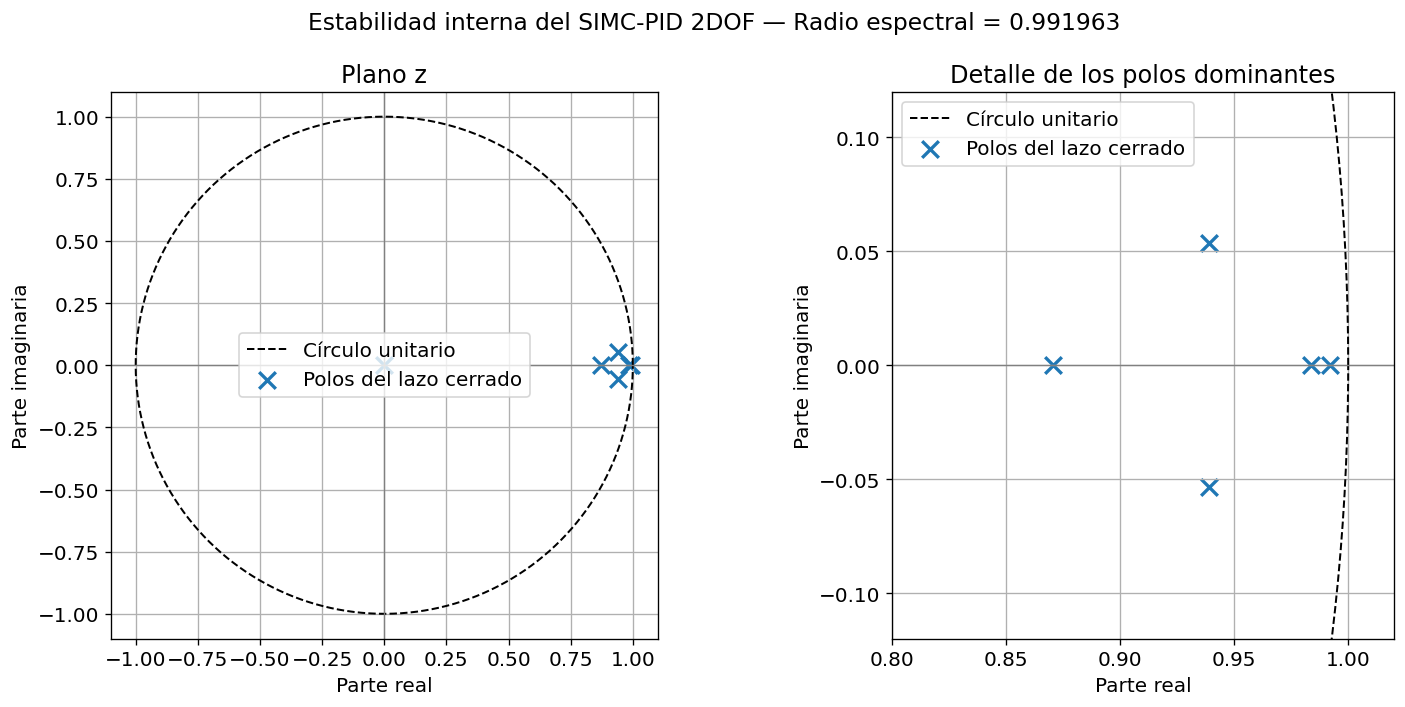

Radio espectral: 0.99196314
Distancia radial mínima al círculo unitario: 0.00803686
Estabilidad interna: ESTABLE


In [ ]:
#Estabilidad interna y ubicación de los polos
# Estabilidad interna del SIMC-PID 2DOF

polos_final = senales_final["polos"]

rho_final = np.max(np.abs(polos_final))

angulo = np.linspace(0, 2*np.pi, 1000)

fig, ax = plt.subplots(
    1, 2,
    figsize=(13, 6)
)

for a in ax:

    a.plot(
        np.cos(angulo),
        np.sin(angulo),
        "k--",
        linewidth=1.2,
        label="Círculo unitario"
    )

    a.scatter(
        polos_final.real,
        polos_final.imag,
        marker="x",
        s=100,
        linewidths=2,
        color="tab:blue",
        label="Polos del lazo cerrado"
    )

    a.axhline(
        0, color="gray", linewidth=0.8
    )

    a.axvline(
        0, color="gray", linewidth=0.8
    )

    a.set_xlabel("Parte real")
    a.set_ylabel("Parte imaginaria")

    a.set_aspect("equal", adjustable="box")
    a.grid(True)
    a.legend(loc="best")

# Vista completa

ax[0].set_xlim(-1.1, 1.1)
ax[0].set_ylim(-1.1, 1.1)

ax[0].set_title("Plano z")

# Ampliación de los polos cercanos a z = 1

ax[1].set_xlim(0.80, 1.02)
ax[1].set_ylim(-0.12, 0.12)

ax[1].set_title("Detalle de los polos dominantes")

fig.suptitle(
    f"Estabilidad interna del SIMC-PID 2DOF "
    f"— Radio espectral = {rho_final:.6f}",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "simc_2dof_polos_lazo_cerrado.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Radio espectral: {rho_final:.8f}")

print(
    f"Distancia radial mínima al círculo unitario: "
    f"{1-rho_final:.8f}"
)

print(
    "Estabilidad interna:",
    "ESTABLE" if rho_final < 1 else "INESTABLE"
)

In [ ]:
#Exportación de los resultados
# Exportación de los resultados finales

datos_final_simc = pd.DataFrame({
    "Tiempo [s]": t_final,
    "Referencia [m]": ref_final,
    "Posicion [m]": y_final,
    "Error [m]": e_final,
    "Control [rad]": u_final,
    "Perturbacion [rad]": du_final,
    "Desviacion [m]": yd_final,
    "Control correctivo [rad]": ud_final,
    "Posicion con perturbacion [m]": y_total_final,
    "Control con perturbacion [rad]": u_total_final
})

datos_final_simc.to_csv(
    "simc_2dof_senales_finales.csv",
    index=False
)

pd.DataFrame(
    [resultado_final]
).to_csv(
    "simc_2dof_indicadores_finales.csv",
    index=False
)

pd.DataFrame({
    "Parte real": polos_final.real,
    "Parte imaginaria": polos_final.imag,
    "Modulo": np.abs(polos_final)
}).to_csv(
    "simc_2dof_polos.csv",
    index=False
)

print("Archivos exportados correctamente.")

Archivos exportados correctamente.


In [ ]:
#Definición del modelo no lineal
# Modelo dinámico no lineal del Ball & Beam

from scipy.integrate import solve_ivp

def dinamica_ball_beam(t, x, v, lineal=False):

    posicion, velocidad, theta_b, omega_b = x

    # Término gravitatorio
    if lineal:
        termino_gravedad = g*theta_b
    else:
        termino_gravedad = g*np.sin(theta_b)

    # Ecuaciones de estado
    dx1 = velocidad

    dx2 = (
        termino_gravedad
        - (b/m)*velocidad
    )

    dx3 = omega_b

    dx4 = (
        -q0*theta_b
        -q1*omega_b
        +ks*v
    )

    return np.array([
        dx1,
        dx2,
        dx3,
        dx4
    ])


print("MODELO DINÁMICO BALL & BEAM")
print(f"m  = {m} kg")
print(f"b  = {b} N s/m")
print(f"g  = {g} m/s²")
print(f"q0 = {q0}")
print(f"q1 = {q1}")
print(f"ks = {ks}")

MODELO DINÁMICO BALL & BEAM
m  = 0.033 kg
b  = 0.15 N s/m
g  = 9.8 m/s²
q0 = 33.1549
q1 = 9.736
ks = 11.4345


In [ ]:
#Simulador con controlador PID 2DOF
# Simulador híbrido: PID discreto + planta continua

def simular_ball_beam_2dof(
    t, ref, du,
    kp, ki, kd,
    br, cr,
    lineal=False
):

    t = np.asarray(t, dtype=float)
    ref = np.asarray(ref, dtype=float)
    du = np.asarray(du, dtype=float)

    N = len(t)

    # Estados de la planta
    x = np.zeros((N, 4))

    # Señales del controlador
    u = np.zeros(N)
    e = np.zeros(N)

    # Componentes del PID
    up = np.zeros(N)
    ui = np.zeros(N)
    ud = np.zeros(N)

    # Estados internos del controlador
    suma_error = 0.0

    r_anterior = 0.0
    y_anterior = 0.0

    for k in range(N):

        # Posición medida
        yk = x[k, 0]

        # Error de seguimiento
        e[k] = ref[k] - yk

        # Acción proporcional ponderada
        up[k] = kp*(br*ref[k] - yk)

        # Acción integral
        suma_error += e[k]

        ui[k] = kp*ki*suma_error

        # Acción derivativa ponderada
        delta_r = ref[k] - r_anterior
        delta_y = yk - y_anterior

        ud[k] = kp*kd*(
            cr*delta_r - delta_y
        )

        # Acción total del controlador
        u[k] = up[k] + ui[k] + ud[k]

        # Actualización de los estados internos
        r_anterior = ref[k]
        y_anterior = yk

        if k < N-1:

            # Entrada total aplicada a la planta
            entrada = u[k] + du[k]

            # Integración continua entre muestras
            sol = solve_ivp(
                dinamica_ball_beam,
                (t[k], t[k+1]),
                x[k],
                args=(entrada, lineal),
                method="RK45",
                rtol=1e-9,
                atol=1e-11,
                max_step=(t[k+1]-t[k])/5
            )

            if not sol.success:
                raise RuntimeError(sol.message)

            x[k+1] = sol.y[:, -1]

    return {
        "t": t,
        "x": x,
        "y": x[:, 0],
        "velocidad": x[:, 1],
        "theta_b": x[:, 2],
        "omega_b": x[:, 3],
        "u": u,
        "e": e,
        "up": up,
        "ui": ui,
        "ud": ud,
        "entrada_planta": u + du
    }

In [ ]:
#Verificación del simulador
# Recuperación de las ganancias seleccionadas

kp_nl = float(resultado_final["kp"])
ki_nl = float(resultado_final["ki"])
kd_nl = float(resultado_final["kd"])

# Perturbación nula
du_cero = np.zeros_like(t_final)

# Simulación de la planta continua linealizada
# con el controlador discreto

sim_lineal = simular_ball_beam_2dof(
    t_final,
    ref_final,
    du_cero,
    kp_nl,
    ki_nl,
    kd_nl,
    br_final,
    cr_final,
    lineal=True
)

# Comparación con el modelo discreto ZOH

dif_y = sim_lineal["y"] - y_final
dif_u = sim_lineal["u"] - u_final

error_max_y = np.max(np.abs(dif_y))
error_max_u = np.max(np.abs(dif_u))

print("="*60)
print("VERIFICACIÓN DEL SIMULADOR")
print("="*60)

print(
    f"Diferencia máxima de posición: "
    f"{error_max_y:.6e} m"
)

print(
    f"Diferencia máxima de control: "
    f"{error_max_u:.6e} rad"
)

verificacion_ok = (
    error_max_y < 1e-6
    and error_max_u < 1e-6
)

if verificacion_ok:
    print("\nVERIFICACIÓN SATISFACTORIA")
else:
    raise RuntimeError(
        "Revisar la equivalencia entre los simuladores."
    )

VERIFICACIÓN DEL SIMULADOR
Diferencia máxima de posición: 2.551473e-12 m
Diferencia máxima de control: 6.766336e-12 rad

VERIFICACIÓN SATISFACTORIA


In [ ]:
#Simulación del modelo no lineal
# Validación sobre el modelo no lineal

# Caso 1: seguimiento de referencia

sim_nl = simular_ball_beam_2dof(
    t_final,
    ref_final,
    du_cero,
    kp_nl,
    ki_nl,
    kd_nl,
    br_final,
    cr_final,
    lineal=False
)

# Caso 2: seguimiento con perturbación

sim_nl_pert = simular_ball_beam_2dof(
    t_final,
    ref_final,
    du_final,
    kp_nl,
    ki_nl,
    kd_nl,
    br_final,
    cr_final,
    lineal=False
)

# Efecto de la perturbación

yd_nl = (
    sim_nl_pert["y"]
    - sim_nl["y"]
)

ud_nl = (
    sim_nl_pert["u"]
    - sim_nl["u"]
)

print("SIMULACIONES NO LINEALES COMPLETADAS")

print(
    f"Ángulo máximo de la barra sin perturbación: "
    f"{np.max(np.abs(np.rad2deg(sim_nl['theta_b']))):.6f}°"
)

print(
    f"Ángulo máximo de la barra con perturbación: "
    f"{np.max(np.abs(np.rad2deg(sim_nl_pert['theta_b']))):.6f}°"
)

SIMULACIONES NO LINEALES COMPLETADAS
Ángulo máximo de la barra sin perturbación: 1.661587°
Ángulo máximo de la barra con perturbación: 1.661587°


In [ ]:
#Indicadores de desempeño
# Indicadores de desempeño del modelo no lineal

indicadores_nl = indicadores_control(
    t_final,
    ref_final,
    sim_nl["y"],
    sim_nl["u"],
    yd_nl,
    sim_nl_pert["u"]
)

indicadores_nl = {
    clave: convertir_escalar(valor)
    for clave, valor in indicadores_nl.items()
}

# Indicadores adicionales

indicadores_nl["Acción correctiva máxima [°]"] = (
    np.max(np.abs(np.rad2deg(ud_nl)))
)

indicadores_nl["Ángulo máximo de barra [°]"] = (
    np.max(
        np.abs(
            np.rad2deg(sim_nl["theta_b"])
        )
    )
)

# Indicadores del modelo lineal

indicadores_lin = indicadores_control(
    t_final,
    ref_final,
    y_final,
    u_final,
    yd_final,
    u_total_final
)

indicadores_lin = {
    clave: convertir_escalar(valor)
    for clave, valor in indicadores_lin.items()
}

indicadores_lin["Acción correctiva máxima [°]"] = (
    np.max(np.abs(np.rad2deg(ud_final)))
)

indicadores_lin["Ángulo máximo de barra [°]"] = (
    np.max(
        np.abs(
            np.rad2deg(sim_lineal["theta_b"])
        )
    )
)

# Tabla comparativa

tabla_lineal_nl = pd.DataFrame({
    "Lineal": indicadores_lin,
    "No lineal": indicadores_nl
})

tabla_lineal_nl["Diferencia absoluta"] = (
    tabla_lineal_nl["No lineal"]
    - tabla_lineal_nl["Lineal"]
).abs()

print("="*60)
print("COMPARACIÓN LINEAL VS. NO LINEAL")
print("="*60)

display(tabla_lineal_nl.round(8))

# Diferencia entre las trayectorias

print("\nDIFERENCIAS ENTRE MODELOS")

print(
    f"Diferencia máxima de posición: "
    f"{1000*np.max(np.abs(sim_nl['y']-y_final)):.8f} mm"
)

print(
    f"Diferencia máxima de actuación: "
    f"{np.max(np.abs(np.rad2deg(sim_nl['u']-u_final))):.8f}°"
)

print(
    f"Diferencia máxima con perturbación: "
    f"{1000*np.max(np.abs(sim_nl_pert['y']-y_total_final)):.8f} mm"
)

print(
    "\nCumple criterio comparativo sin perturbación:",
    np.max(np.abs(np.rad2deg(sim_nl["u"])))
    <= u_ref_ift
)

print(
    "Cumple criterio comparativo con perturbación:",
    np.max(np.abs(np.rad2deg(sim_nl_pert["u"])))
    <= u_ref_ift
)

COMPARACIÓN LINEAL VS. NO LINEAL


,Lineal,No lineal,Diferencia absoluta
Sobreimpulso [%],0.030687,0.030859,1.719100e-04
Establecimiento [s],5.000000,5.000000,0.000000e+00
Control máximo [°],5.463521,5.463522,9.000000e-07
Control máximo con perturbación [°],5.463521,5.463522,9.000000e-07
Control RMS [°],0.651628,0.651660,3.211000e-05
RMSE referencia [m],0.013435,0.013435,2.800000e-07
Error final [m],0.000000,-0.000000,0.000000e+00
Desviación por perturbación [mm],7.536677,7.536657,1.985000e-05
Acción correctiva máxima [°],0.817160,0.817158,2.080000e-06
Ángulo máximo de barra [°],1.661568,1.661587,1.875000e-05



DIFERENCIAS ENTRE MODELOS
Diferencia máxima de posición: 0.00376796 mm
Diferencia máxima de actuación: 0.00040987°
Diferencia máxima con perturbación: 0.00376796 mm

Cumple criterio comparativo sin perturbación: True
Cumple criterio comparativo con perturbación: True


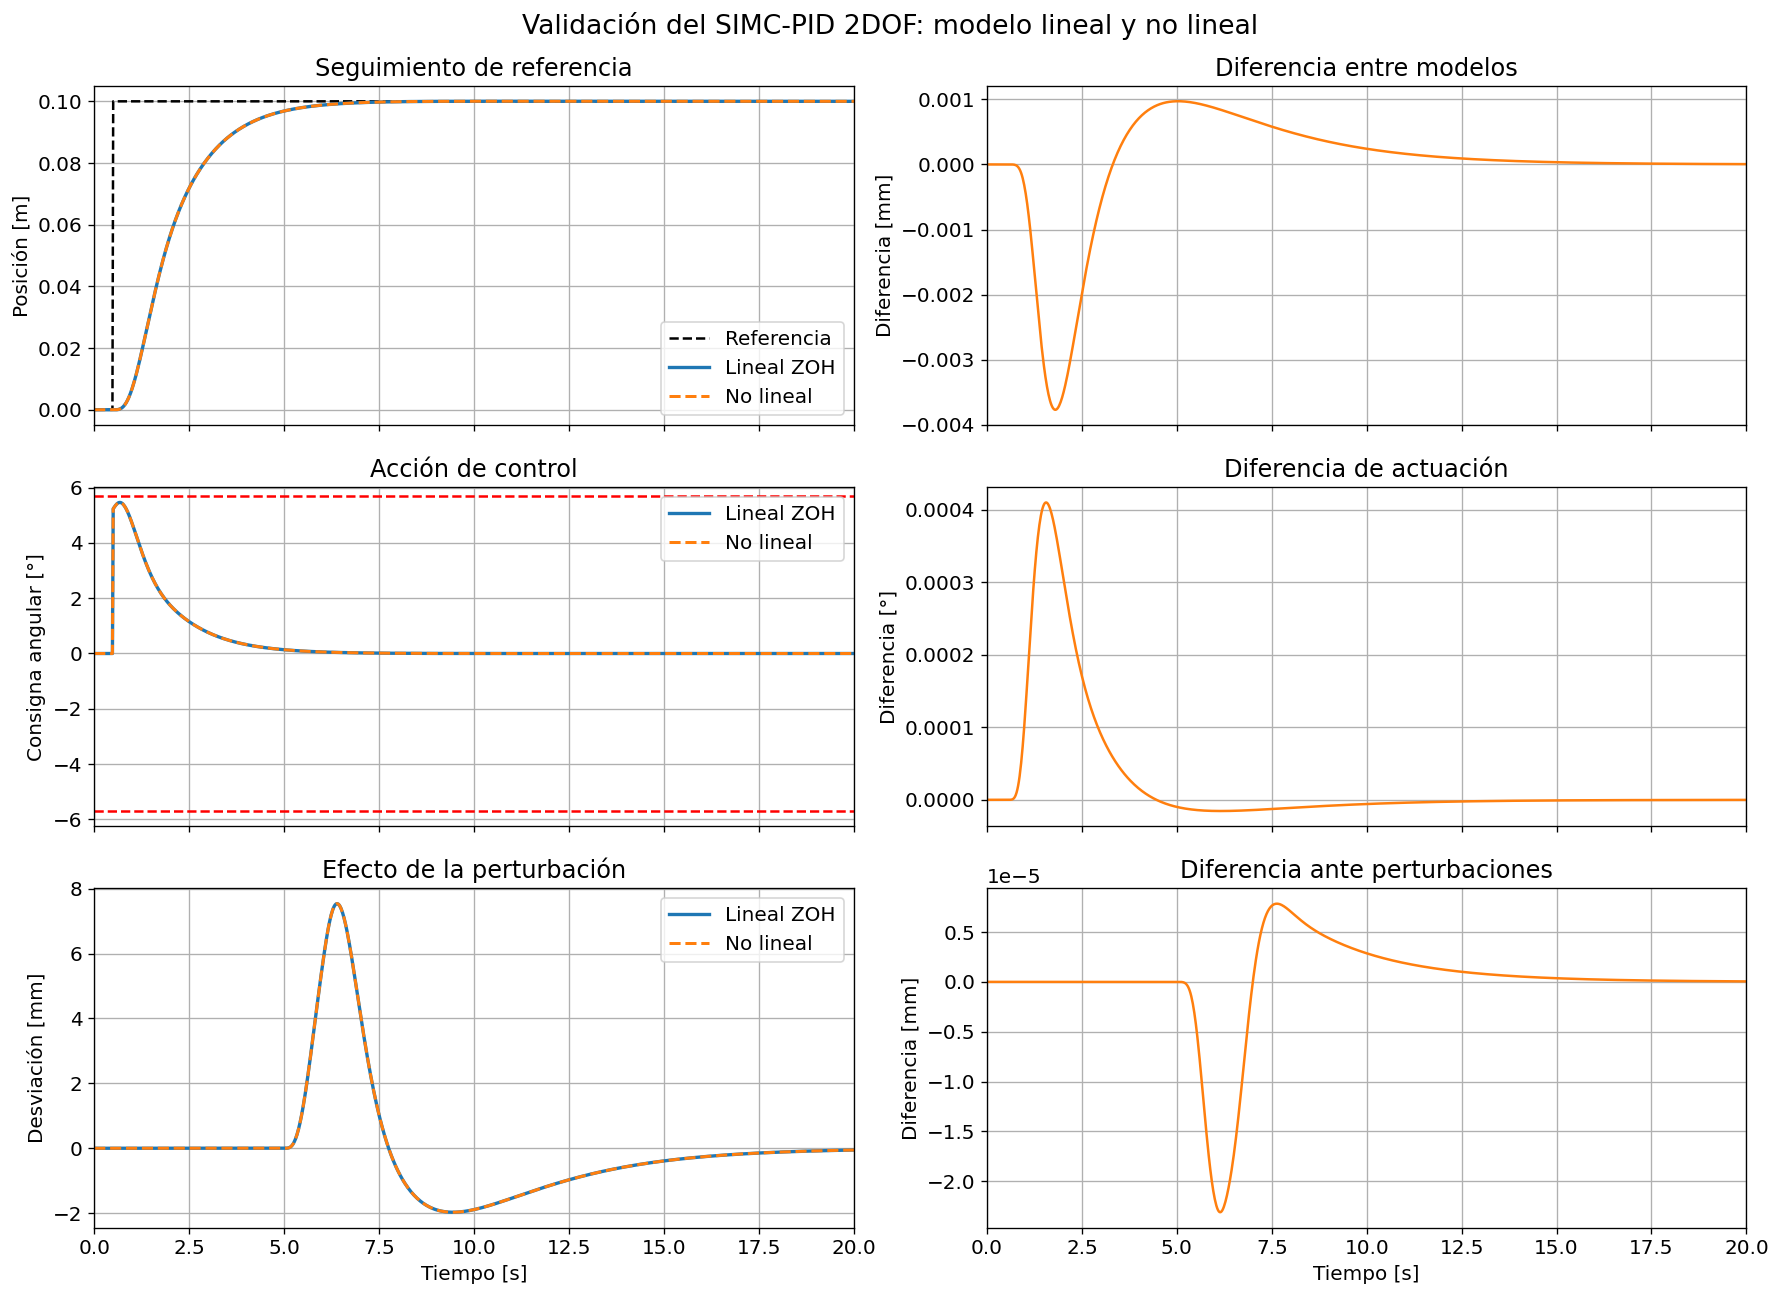

In [ ]:
#Comparación gráfica lineal vs. no lineal
# Comparación de las respuestas temporales

fig, ax = plt.subplots(
    3, 2,
    figsize=(15, 11),
    sharex=True
)

# Seguimiento de referencia

ax[0, 0].plot(
    t_final, ref_final,
    "k--", label="Referencia"
)

ax[0, 0].plot(
    t_final, y_final,
    linewidth=2,
    label="Lineal ZOH"
)

ax[0, 0].plot(
    t_final, sim_nl["y"],
    "--", linewidth=1.8,
    label="No lineal"
)

ax[0, 0].set_title("Seguimiento de referencia")
ax[0, 0].set_ylabel("Posición [m]")
ax[0, 0].legend()

# Diferencia entre posiciones

ax[0, 1].plot(
    t_final,
    1000*(sim_nl["y"]-y_final),
    color="tab:orange"
)

ax[0, 1].set_title("Diferencia entre modelos")
ax[0, 1].set_ylabel("Diferencia [mm]")

# Acción de control

ax[1, 0].plot(
    t_final,
    np.rad2deg(u_final),
    linewidth=2,
    label="Lineal ZOH"
)

ax[1, 0].plot(
    t_final,
    np.rad2deg(sim_nl["u"]),
    "--", linewidth=1.8,
    label="No lineal"
)

for signo in [-1, 1]:
    ax[1, 0].axhline(
        signo*u_ref_ift,
        color="red",
        linestyle="--"
    )

ax[1, 0].set_title("Acción de control")
ax[1, 0].set_ylabel("Consigna angular [°]")
ax[1, 0].legend()

# Diferencia entre acciones de control

ax[1, 1].plot(
    t_final,
    np.rad2deg(sim_nl["u"]-u_final),
    color="tab:orange"
)

ax[1, 1].set_title("Diferencia de actuación")
ax[1, 1].set_ylabel("Diferencia [°]")

# Respuesta frente a perturbaciones

ax[2, 0].plot(
    t_final,
    1000*yd_final,
    linewidth=2,
    label="Lineal ZOH"
)

ax[2, 0].plot(
    t_final,
    1000*yd_nl,
    "--", linewidth=1.8,
    label="No lineal"
)

ax[2, 0].set_title("Efecto de la perturbación")
ax[2, 0].set_ylabel("Desviación [mm]")
ax[2, 0].legend()

# Diferencia del efecto de perturbación

ax[2, 1].plot(
    t_final,
    1000*(yd_nl-yd_final),
    color="tab:orange"
)

ax[2, 1].set_title("Diferencia ante perturbaciones")
ax[2, 1].set_ylabel("Diferencia [mm]")

# Configuración general

for a in ax.flat:
    a.grid(True)
    a.set_xlim(0, 20)

for a in ax[-1, :]:
    a.set_xlabel("Tiempo [s]")

fig.suptitle(
    "Validación del SIMC-PID 2DOF: "
    "modelo lineal y no lineal",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "simc_2dof_comparacion_lineal_nolineal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

VALIDEZ DE LA LINEALIZACIÓN
Ángulo máximo sin perturbación: 1.66158673°
Ángulo máximo con perturbación: 1.66158673°
Error máximo de linealización sin perturbación: 0.01401623 %
Error máximo de linealización con perturbación: 0.01401623 %


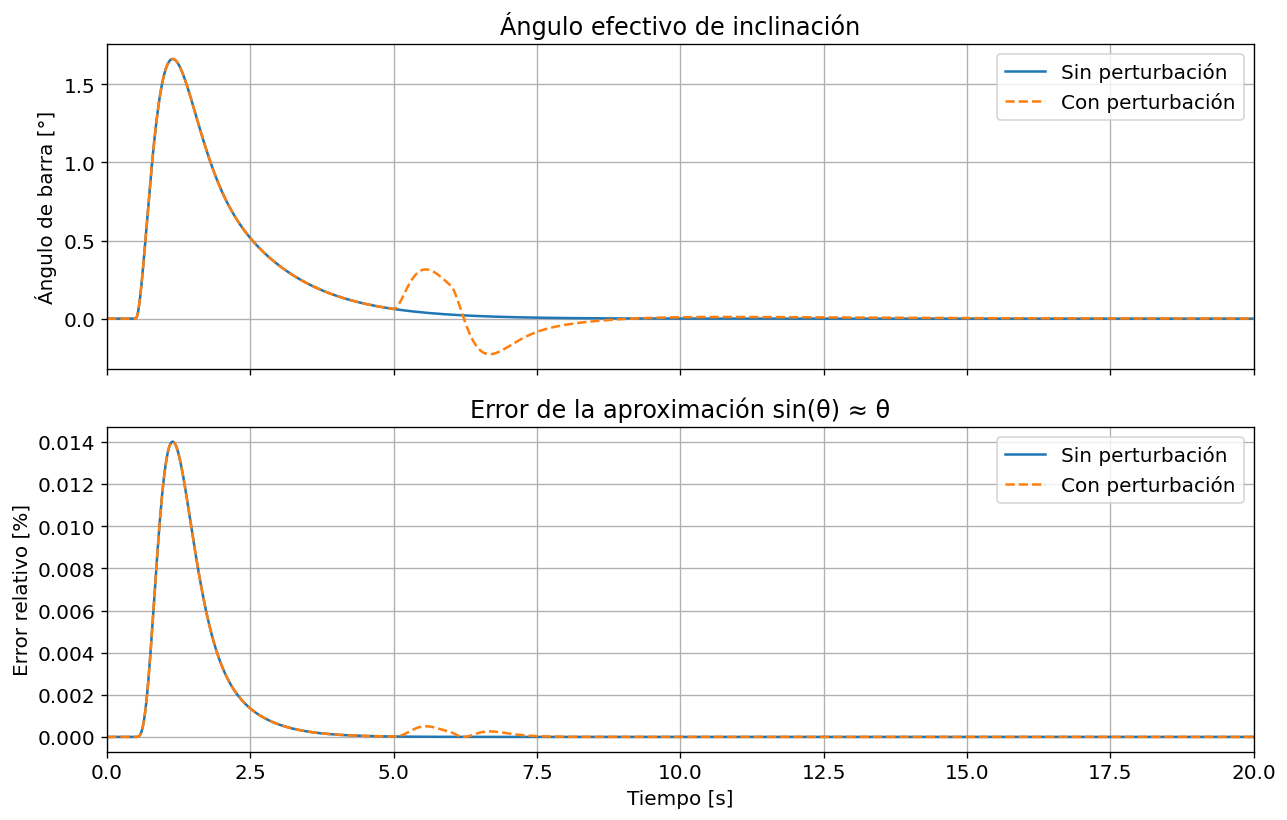

In [ ]:
#Validez de la aproximación de pequeños ángulos
# Evaluación de la aproximación de pequeños ángulos

theta_nl = sim_nl["theta_b"]
theta_nl_pert = sim_nl_pert["theta_b"]

def error_linealizacion(theta):

    theta = np.asarray(theta)

    error = np.zeros_like(theta)

    mascara = np.abs(theta) > 1e-10

    error[mascara] = 100*np.abs(
        (
            np.sin(theta[mascara])
            - theta[mascara]
        )/theta[mascara]
    )

    return error


err_sin = error_linealizacion(theta_nl)

err_sin_pert = error_linealizacion(
    theta_nl_pert
)

print("="*60)
print("VALIDEZ DE LA LINEALIZACIÓN")
print("="*60)

print(
    f"Ángulo máximo sin perturbación: "
    f"{np.max(np.abs(np.rad2deg(theta_nl))):.8f}°"
)

print(
    f"Ángulo máximo con perturbación: "
    f"{np.max(np.abs(np.rad2deg(theta_nl_pert))):.8f}°"
)

print(
    f"Error máximo de linealización sin perturbación: "
    f"{np.max(err_sin):.8f} %"
)

print(
    f"Error máximo de linealización con perturbación: "
    f"{np.max(err_sin_pert):.8f} %"
)

fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

ax[0].plot(
    t_final,
    np.rad2deg(theta_nl),
    label="Sin perturbación"
)

ax[0].plot(
    t_final,
    np.rad2deg(theta_nl_pert),
    "--",
    label="Con perturbación"
)

ax[0].set_ylabel("Ángulo de barra [°]")
ax[0].set_title("Ángulo efectivo de inclinación")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(
    t_final,
    err_sin,
    label="Sin perturbación"
)

ax[1].plot(
    t_final,
    err_sin_pert,
    "--",
    label="Con perturbación"
)

ax[1].set_ylabel("Error relativo [%]")
ax[1].set_xlabel("Tiempo [s]")
ax[1].set_title("Error de la aproximación sin(θ) ≈ θ")
ax[1].legend()
ax[1].grid(True)
ax[1].set_xlim(0, 20)

plt.tight_layout()

plt.savefig(
    "simc_2dof_validez_linealizacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Exportación de resultados
# Exportación de la validación no lineal

tabla_lineal_nl.to_csv(
    "simc_2dof_comparacion_lineal_nolineal.csv"
)

datos_nl = pd.DataFrame({

    "Tiempo [s]": t_final,

    "Referencia [m]": ref_final,

    "Posicion lineal [m]": y_final,

    "Posicion no lineal [m]": sim_nl["y"],

    "Control lineal [rad]": u_final,

    "Control no lineal [rad]": sim_nl["u"],

    "Angulo barra [rad]": theta_nl,

    "Angulo barra perturbado [rad]": theta_nl_pert,

    "Perturbacion [rad]": du_final,

    "Desviacion lineal [m]": yd_final,

    "Desviacion no lineal [m]": yd_nl,

    "Posicion NL perturbada [m]": sim_nl_pert["y"],

    "Control NL perturbado [rad]": sim_nl_pert["u"],

    "Error linealizacion [%]": err_sin,

    "Error linealizacion perturbado [%]": err_sin_pert
})

datos_nl.to_csv(
    "simc_2dof_senales_nolineales.csv",
    index=False
)

print("Resultados exportados correctamente.")

Resultados exportados correctamente.


In [ ]:
#Recuperación del modelo BJ LC
num_bj = np.array([
    8.3496e-6,
    7.6996e-6,
   -1.3479e-6,
    9.0805e-7
])

den_bj = np.array([
     1.0,
    -3.7232,
     5.1982,
    -3.2257,
     0.7507,
     0.0
])

Gm_bj = ct.tf(num_bj, den_bj, Ts)

print("="*60)
print("MODELO IDENTIFICADO BJ LC")
print("="*60)

print(Gm_bj)

print("\nPolos:")
print(ct.poles(Gm_bj))

print("\nCeros:")
print(ct.zeros(Gm_bj))

print("\nGrado relativo:")
print(len(den_bj)-len(num_bj))

print("\nEvaluación del denominador en z=1:")
print(np.polyval(den_bj, 1.0))

MODELO IDENTIFICADO BJ LC
<TransferFunction>: sys[706]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

  8.35e-06 z^3 + 7.7e-06 z^2 - 1.348e-06 z + 9.081e-07
  ----------------------------------------------------
   z^5 - 3.723 z^4 + 5.198 z^3 - 3.226 z^2 + 0.7507 z

Polos:
[1.        +0.j         0.91281136+0.05601737j 0.91281136-0.05601737j
 0.89757728+0.j         0.        +0.j        ]

Ceros:
[-1.14586338+0.j          0.11185571+0.28705077j  0.11185571-0.28705077j]

Grado relativo:
2

Evaluación del denominador en z=1:
3.3306690738754696e-16


In [ ]:
#Verificación del modelo recuperado
# CELDA 50
# Recuperación de la estructura integral

polos_bj_original = np.roots(den_bj)

indice_integrador = np.argmin(
    np.abs(polos_bj_original - 1)
)

polo_integrador = polos_bj_original[
    indice_integrador
]

print("Polo más próximo a z=1:")
print(polo_integrador)

print("\nDistancia a z=1:")
print(abs(polo_integrador - 1))

# División por el factor integral

den_vel_bj, residuo_bj = np.polydiv(
    den_bj,
    [1.0, -1.0]
)

print("\nResiduo de la división:")
print(residuo_bj)

# Reconstrucción con integrador exacto

den_bj_corr = np.polymul(
    den_vel_bj,
    [1.0, -1.0]
)

Gm_bj_corr = ct.tf(
    num_bj,
    den_bj_corr,
    Ts
)

print("\nDenominador original:")
print(den_bj)

print("\nDenominador reconstruido:")
print(den_bj_corr)

print("\nPolos del modelo reconstruido:")
print(ct.poles(Gm_bj_corr))

print("\nCeros del modelo reconstruido:")
print(ct.zeros(Gm_bj_corr))

print("\nPolos de la dinámica de velocidad:")
print(np.roots(den_vel_bj))

print(
    "\nEstabilidad de la dinámica de velocidad:",
    np.all(np.abs(np.roots(den_vel_bj)) < 1)
)

Polo más próximo a z=1:
(0.9999999999984539+0j)

Distancia a z=1:
1.546096584092993e-12

Residuo de la división:
[3.33066907e-16]

Denominador original:
[ 1.     -3.7232  5.1982 -3.2257  0.7507  0.    ]

Denominador reconstruido:
[ 1.00000000e+00 -3.72320000e+00  5.19820000e+00 -3.22570000e+00
  7.50700000e-01 -3.33066907e-16]

Polos del modelo reconstruido:
[1.00000000e+00+0.j         9.12811359e-01+0.05601737j
 9.12811359e-01-0.05601737j 8.97577282e-01+0.j
 4.43675113e-16+0.j        ]

Ceros del modelo reconstruido:
[-1.14586338+0.j          0.11185571+0.28705077j  0.11185571-0.28705077j]

Polos de la dinámica de velocidad:
[9.12811359e-01+0.05601737j 9.12811359e-01-0.05601737j
 8.97577282e-01+0.j         4.43675113e-16+0.j        ]

Estabilidad de la dinámica de velocidad: True


In [ ]:
#Factorización del modelo BJ LC
# CELDA 51
# Factorización del modelo BJ LC

ceros_bj = np.roots(num_bj)

ceros_no_minimos = ceros_bj[
    np.abs(ceros_bj) >= 1
]

assert len(ceros_no_minimos) == 1, (
    "Se esperaba un único cero de fase no mínima."
)

zu = float(
    np.real(ceros_no_minimos[0])
)

rg = len(den_bj_corr)-len(num_bj)

# Factor no invertible

num_plus = np.array([1.0, -zu])

den_plus = np.r_[
    1.0-zu,
    np.zeros(rg+1)
]

Gplus = ct.tf(
    num_plus,
    den_plus,
    Ts
)

# Factor invertible

num_min, residuo_min = np.polydiv(
    num_bj,
    [1.0, -zu]
)

assert np.max(np.abs(residuo_min)) < 1e-12

num_minus = np.polymul(
    (1.0-zu)*num_min,
    np.r_[1.0, np.zeros(rg+1)]
)

den_minus = den_bj_corr.copy()

# Cancelación explícita del factor común z

num_minus = num_minus[:-1]
den_minus = den_minus[:-1]

Gminus = ct.tf(
    num_minus,
    den_minus,
    Ts
)

print("="*60)
print("FACTORIZACIÓN DEL MODELO BJ LC")
print("="*60)

print(f"Cero de fase no mínima: {zu:.10f}")
print(f"Grado relativo: {rg}")

print("\nGplus:")
print(Gplus)

print("\nGminus:")
print(Gminus)

print("\nGanancia estática Gplus:")
print(ct.dcgain(Gplus))

print("\nCeros de Gminus:")
print(ct.zeros(Gminus))

FACTORIZACIÓN DEL MODELO BJ LC
Cero de fase no mínima: -1.1458633805
Grado relativo: 2

Gplus:
<TransferFunction>: sys[708]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

  z + 1.146
  ---------
  2.146 z^3

Gminus:
<TransferFunction>: sys[709]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

  1.792e-05 z^4 - 4.008e-06 z^3 + 1.701e-06 z^2
  ----------------------------------------------
  z^4 - 3.723 z^3 + 5.198 z^2 - 3.226 z + 0.7507

Ganancia estática Gplus:
1.0

Ceros de Gminus:
[0.11185571+0.28705077j 0.11185571-0.28705077j 0.        +0.j
 0.        +0.j        ]


VERIFICACIÓN DE LA FACTORIZACIÓN
Error relativo máximo: 2.55823763e-08

FACTORIZACIÓN SATISFACTORIA


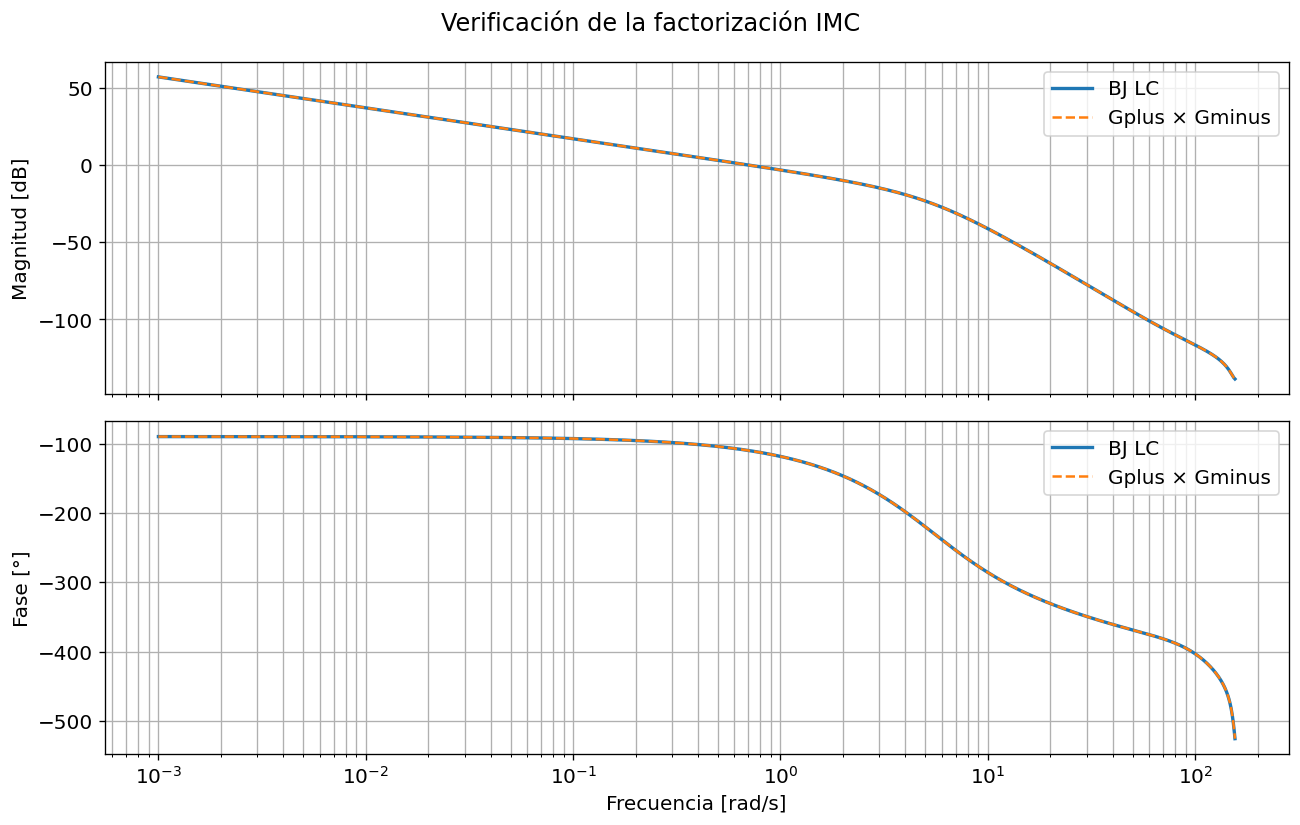

In [ ]:
#Verificación de la factorización
# CELDA 52
# Verificación de la factorización

Gm_reconstruido = Gplus*Gminus

w_verificacion = np.geomspace(
    1e-3,
    0.99*np.pi/Ts,
    2000
)

z_verificacion = np.exp(
    1j*w_verificacion*Ts
)

H_bj = np.array([
    ct.evalfr(Gm_bj_corr, z)
    for z in z_verificacion
])

H_factores = np.array([
    ct.evalfr(Gm_reconstruido, z)
    for z in z_verificacion
])

error_factorizacion = np.max(
    np.abs(H_bj-H_factores)
    / np.maximum(np.abs(H_bj), 1e-15)
)

print("="*60)
print("VERIFICACIÓN DE LA FACTORIZACIÓN")
print("="*60)

print(
    f"Error relativo máximo: "
    f"{error_factorizacion:.8e}"
)

assert error_factorizacion < 1e-5, (
    "Revisar la factorización."
)

print("\nFACTORIZACIÓN SATISFACTORIA")

fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

ax[0].semilogx(
    w_verificacion,
    20*np.log10(np.abs(H_bj)),
    linewidth=2,
    label="BJ LC"
)

ax[0].semilogx(
    w_verificacion,
    20*np.log10(np.abs(H_factores)),
    "--",
    label="Gplus × Gminus"
)

ax[0].set_ylabel("Magnitud [dB]")

ax[1].semilogx(
    w_verificacion,
    np.rad2deg(np.unwrap(np.angle(H_bj))),
    linewidth=2,
    label="BJ LC"
)

ax[1].semilogx(
    w_verificacion,
    np.rad2deg(
        np.unwrap(np.angle(H_factores))
    ),
    "--",
    label="Gplus × Gminus"
)

ax[1].set_ylabel("Fase [°]")
ax[1].set_xlabel("Frecuencia [rad/s]")

for a in ax:
    a.grid(True, which="both")
    a.legend()

fig.suptitle(
    "Verificación de la factorización IMC"
)

plt.tight_layout()
plt.show()

In [ ]:
#Construcción del filtro IMC
# CELDA 53
# Filtro IMC seleccionado

n_imc = 4
beta_imc = 0.5

a_imc = np.exp(-Ts/beta_imc)

num_f = np.r_[
    (1-a_imc)**n_imc,
    np.zeros(n_imc)
]

den_f = np.poly(
    np.full(n_imc, a_imc)
)

F_imc = ct.tf(
    num_f,
    den_f,
    Ts
)

T_obj_imc = Gplus*F_imc

print("="*60)
print("FILTRO IMC SELECCIONADO")
print("="*60)

print(f"Orden: {n_imc}")
print(f"Beta: {beta_imc} s")
print(f"a: {a_imc:.10f}")

print("\nFiltro IMC:")
print(F_imc)

print("\nRespuesta objetivo:")
print(T_obj_imc)

print("\nGanancia estática del filtro:")
print(ct.dcgain(F_imc))

print("\nPolos del filtro:")
print(ct.poles(F_imc))

FILTRO IMC SELECCIONADO
Orden: 4
Beta: 0.5 s
a: 0.9607894392

Filtro IMC:
<TransferFunction>: sys[711]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

                  2.364e-06 z^4
  ----------------------------------------------
  z^4 - 3.843 z^3 + 5.539 z^2 - 3.548 z + 0.8521

Respuesta objetivo:
<TransferFunction>: sys[712]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

                2.364e-06 z^5 + 2.709e-06 z^4
  ---------------------------------------------------------
  2.146 z^7 - 8.247 z^6 + 11.89 z^5 - 7.613 z^4 + 1.829 z^3

Ganancia estática del filtro:
0.9999999999022066

Polos del filtro:
[0.96092693+0.0001375j  0.96092693-0.0001375j  0.96065194+0.00013749j
 0.96065194-0.00013749j]


In [ ]:
#Construcción del controlador Q
# CELDA 54
# Construcción del controlador interno Q

def cancelar_origen(num, den, tol=1e-14):

    num = np.asarray(num, dtype=float).copy()
    den = np.asarray(den, dtype=float).copy()

    while (
        len(num) > 1
        and len(den) > 1
        and abs(num[-1]) < tol
        and abs(den[-1]) < tol
    ):
        num = num[:-1]
        den = den[:-1]

    return num, den


num_Q = np.polymul(
    den_minus,
    num_f
)

den_Q = np.polymul(
    num_minus,
    den_f
)

num_Q, den_Q = cancelar_origen(
    num_Q, den_Q
)

Q_imc = ct.tf(
    num_Q,
    den_Q,
    Ts
)

polos_Q = ct.poles(Q_imc)

print("="*60)
print("CONTROLADOR INTERNO IMC")
print("="*60)

print(Q_imc)

print("\nPolos de Q:")
print(polos_Q)

print(
    "\nRadio espectral de Q:",
    np.max(np.abs(polos_Q))
)

print(
    "Q estable:",
    np.all(np.abs(polos_Q) < 1)
)

print(
    "Q propio:",
    len(num_Q) <= len(den_Q)
)

CONTROLADOR INTERNO IMC
<TransferFunction>: sys[713]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

              2.364e-06 z^6 - 8.801e-06 z^5 + 1.229e-05 z^4 - 7.625e-06 z^3 + 1.775e-06 z^2
  ------------------------------------------------------------------------------------------------------
  1.792e-05 z^6 - 7.287e-05 z^5 + 0.0001163 z^4 - 9.23e-05 z^3 + 3.891e-05 z^2 - 9.448e-06 z + 1.449e-06

Polos de Q:
[0.96104093+0.00000000e+00j 0.96078943+2.51479238e-04j
 0.96078943-2.51479238e-04j 0.96053797+0.00000000e+00j
 0.11185571+2.87050766e-01j 0.11185571-2.87050766e-01j]

Radio espectral de Q: 0.961040930014891
Q estable: True
Q propio: True


In [ ]:
#Controlador equivalente realimentado
# CELDA 55
# Construcción algebraica del controlador equivalente

# Factor 1 - Gplus*F

num_1_T = np.polysub(

    np.polymul(
        den_plus,
        den_f
    ),

    np.polymul(
        num_plus,
        num_f
    )
)

# Numerador y denominador de C_IMC

num_C = np.polymul(
    np.polymul(num_f, den_minus),
    den_plus
)

den_C = np.polymul(
    num_minus,
    num_1_T
)

# Cancelación de factores comunes en z=0

num_C, den_C = cancelar_origen(
    num_C, den_C
)

# Cancelación algebraica del factor z-1

num_C_red, res_num = np.polydiv(
    num_C,
    [1.0, -1.0]
)

den_C_red, res_den = np.polydiv(
    den_C,
    [1.0, -1.0]
)

error_num = (
    np.max(np.abs(res_num))
    / np.max(np.abs(num_C))
)

error_den = (
    np.max(np.abs(res_den))
    / np.max(np.abs(den_C))
)

print("="*60)
print("CANCELACIÓN DEL FACTOR INTEGRAL")
print("="*60)

print(
    f"Residuo relativo numerador: "
    f"{error_num:.8e}"
)

print(
    f"Residuo relativo denominador: "
    f"{error_den:.8e}"
)

assert error_num < 1e-10
assert error_den < 1e-10

# Normalización

factor_norm = den_C_red[0]

num_C_red = num_C_red/factor_norm
den_C_red = den_C_red/factor_norm

C_imc = ct.tf(
    num_C_red,
    den_C_red,
    Ts
)

print("\nCONTROLADOR EQUIVALENTE IMC")
print(C_imc)

print("\nPolos del controlador:")
print(ct.poles(C_imc))

print("\nCeros del controlador:")
print(ct.zeros(C_imc))

print(
    "\nOrden del controlador:",
    len(den_C_red)-1
)

print(
    "Controlador propio:",
    len(num_C_red) <= len(den_C_red)
)

CANCELACIÓN DEL FACTOR INTEGRAL
Residuo relativo numerador: 1.60621263e-17
Residuo relativo denominador: 7.80348337e-17

CONTROLADOR EQUIVALENTE IMC
<TransferFunction>: sys[714]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
dt = 0.02

  0.1319 z^5 - 0.3593 z^4 + 0.3265 z^3 - 0.09904 z^2 - 1.102e-17 z - 1.102e-17
  ----------------------------------------------------------------------------
          z^5 - 3.067 z^4 + 3.426 z^3 - 1.725 z^2 + 0.4465 z - 0.08088

Polos del controlador:
[0.96022371+0.03863886j 0.96022371-0.03863886j 0.92271034+0.j
 0.11185571+0.28705077j 0.11185571-0.28705077j]

Ceros del controlador:
[ 9.12811359e-01+5.60173696e-02j  9.12811359e-01-5.60173696e-02j
  8.97577282e-01+0.00000000e+00j -2.38955576e-16+1.05461709e-08j
 -2.38955576e-16-1.05461709e-08j]

Orden del controlador: 5
Controlador propio: True


VERIFICACIÓN DE LA RESPUESTA OBJETIVO
Error absoluto máximo: 3.61404593e-10


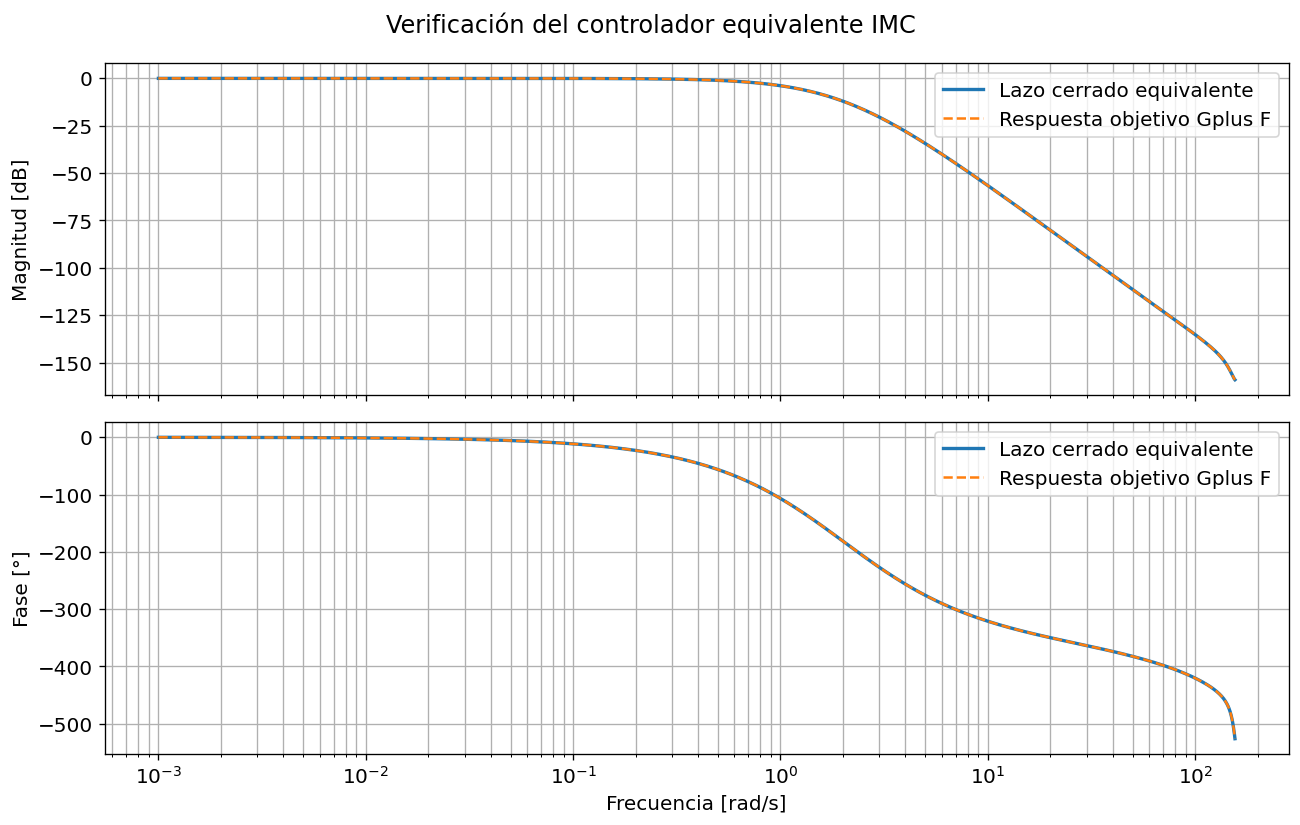

In [ ]:
#Verificación de la respuesta objetivo
# CELDA 56
# Verificación de la respuesta objetivo IMC

H_modelo = np.array([
    ct.evalfr(Gm_bj_corr, z)
    for z in z_verificacion
])

H_controlador = np.array([
    ct.evalfr(C_imc, z)
    for z in z_verificacion
])

H_lazo = (
    H_modelo*H_controlador
    / (1 + H_modelo*H_controlador)
)

H_objetivo = np.array([
    ct.evalfr(Gplus, z)
    * ct.evalfr(F_imc, z)
    for z in z_verificacion
])

error_objetivo = np.max(
    np.abs(H_lazo-H_objetivo)
)

print("="*60)
print("VERIFICACIÓN DE LA RESPUESTA OBJETIVO")
print("="*60)

print(
    f"Error absoluto máximo: "
    f"{error_objetivo:.8e}"
)

fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

ax[0].semilogx(
    w_verificacion,
    20*np.log10(np.abs(H_lazo)),
    linewidth=2,
    label="Lazo cerrado equivalente"
)

ax[0].semilogx(
    w_verificacion,
    20*np.log10(np.abs(H_objetivo)),
    "--",
    label="Respuesta objetivo Gplus F"
)

ax[0].set_ylabel("Magnitud [dB]")

ax[1].semilogx(
    w_verificacion,
    np.rad2deg(
        np.unwrap(np.angle(H_lazo))
    ),
    linewidth=2,
    label="Lazo cerrado equivalente"
)

ax[1].semilogx(
    w_verificacion,
    np.rad2deg(
        np.unwrap(np.angle(H_objetivo))
    ),
    "--",
    label="Respuesta objetivo Gplus F"
)

ax[1].set_ylabel("Fase [°]")
ax[1].set_xlabel("Frecuencia [rad/s]")

for a in ax:
    a.grid(True, which="both")
    a.legend()

fig.suptitle(
    "Verificación del controlador equivalente IMC"
)

plt.tight_layout()

plt.savefig(
    "imc_verificacion_controlador_equivalente.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Estabilidad interna
# CELDA 57
# Estabilidad interna del controlador IMC

def construir_lazo_imc(planta, controlador):

    P = ct.ss(planta)
    C = ct.ss(controlador)

    Ap = np.asarray(P.A)
    Bp = np.asarray(P.B)
    Cp = np.asarray(P.C)
    Dp = np.asarray(P.D)

    Ac = np.asarray(C.A)
    Bc = np.asarray(C.B)
    Cc = np.asarray(C.C)
    Dc = np.asarray(C.D)

    assert np.allclose(Dp, 0), (
        "La planta debe ser estrictamente propia."
    )

    nc = Ac.shape[0]

    Acl = np.block([
        [Ap - Bp @ Dc @ Cp, Bp @ Cc],
        [-Bc @ Cp,          Ac]
    ])

    Br = np.vstack([
        Bp @ Dc,
        Bc
    ])

    Bd = np.vstack([
        Bp,
        np.zeros((nc, 1))
    ])

    Cy = np.hstack([
        Cp,
        np.zeros((1, nc))
    ])

    Cu = np.hstack([
        -Dc @ Cp,
        Cc
    ])

    Bcl = np.hstack([Br, Bd])

    Ccl = np.vstack([Cy, Cu])

    Dcl = np.array([
        [0.0, 0.0],
        [Dc.item(), 0.0]
    ])

    sistema = ct.ss(
        Acl, Bcl, Ccl, Dcl, Ts
    )

    polos = np.linalg.eigvals(Acl)

    return sistema, polos


# Modelo identificado BJ LC

sistema_imc_bj, polos_imc_bj = (
    construir_lazo_imc(
        Gm_bj_corr,
        C_imc
    )
)

# Modelo nominal ZOH

sistema_imc_nom, polos_imc_nom = (
    construir_lazo_imc(
        Gd,
        C_imc
    )
)

print("="*60)
print("ESTABILIDAD INTERNA DEL IMC")
print("="*60)

for nombre, polos in [

    ("BJ LC", polos_imc_bj),

    ("Nominal ZOH", polos_imc_nom)

]:

    rho = float(
        np.max(np.abs(polos))
    )

    print(f"\nModelo: {nombre}")

    print(f"Radio espectral: {rho:.8f}")

    print(
        "Estabilidad interna:",
        "ESTABLE" if rho < 1 else "INESTABLE"
    )

    print("\nPolos:")

    for p in polos:

        print(
            f"{p.real:+.8f} "
            f"{p.imag:+.8f}j "
            f"|z| = {abs(p):.8f}"
        )

ESTABILIDAD INTERNA DEL IMC

Modelo: BJ LC
Radio espectral: 0.96081767
Estabilidad interna: ESTABLE

Polos:
+0.00000000 +0.00000000j |z| = 0.00000000
+0.91281136 +0.05601737j |z| = 0.91452858
+0.91281136 -0.05601737j |z| = 0.91452858
+0.96081767 +0.00000000j |z| = 0.96081767
+0.96078974 +0.00002853j |z| = 0.96078974
+0.96078974 -0.00002853j |z| = 0.96078974
+0.96076061 +0.00000000j |z| = 0.96076061
+0.89757728 +0.00000000j |z| = 0.89757728
+0.11185571 +0.28705077j |z| = 0.30807441
+0.11185571 -0.28705077j |z| = 0.30807441

Modelo: Nominal ZOH
Radio espectral: 0.97738832
Estabilidad interna: ESTABLE

Polos:
+0.97729597 +0.01343548j |z| = 0.97738832
+0.97729597 -0.01343548j |z| = 0.97738832
+0.90512845 +0.05580069j |z| = 0.90684686
+0.90512845 -0.05580069j |z| = 0.90684686
+0.94685116 +0.02329650j |z| = 0.94713771
+0.94685116 -0.02329650j |z| = 0.94713771
+0.90873479 +0.00000000j |z| = 0.90873479
+0.11185580 +0.28705079j |z| = 0.30807446
+0.11185580 -0.28705079j |z| = 0.30807446


In [ ]:
#Validación temporal del IMC
# CELDA 58
# Validación temporal del controlador IMC

t_imc = np.arange(0, 60 + Ts/2, Ts)

ref_imc = 0.1*(t_imc >= 0.5)

du_imc = np.deg2rad(1)*(
    (t_imc >= 5) & (t_imc < 6)
)

# Respuesta del modelo objetivo

_, y_obj_imc = ct.forced_response(
    ct.ss(T_obj_imc),
    t_imc,
    ref_imc
)

y_obj_imc = np.asarray(y_obj_imc).ravel()

# Sistemas a evaluar

sistemas_imc = {
    "BJ LC": sistema_imc_bj,
    "Nominal ZOH": sistema_imc_nom
}

senales_imc = {}

for nombre, sistema in sistemas_imc.items():

    # Seguimiento sin perturbación

    entrada_ref = np.vstack([
        ref_imc,
        np.zeros_like(t_imc)
    ])

    respuesta_ref = ct.forced_response(
        sistema,
        t_imc,
        entrada_ref
    )

    y, u = np.asarray(respuesta_ref.outputs)

    # Respuesta exclusiva a la perturbación

    entrada_pert = np.vstack([
        np.zeros_like(t_imc),
        du_imc
    ])

    respuesta_pert = ct.forced_response(
        sistema,
        t_imc,
        entrada_pert
    )

    yd, ud = np.asarray(respuesta_pert.outputs)

    # Respuesta total por superposición

    y_total = y + yd
    u_total = u + ud

    senales_imc[nombre] = {
        "y": y,
        "u": u,
        "yd": yd,
        "ud": ud,
        "y_total": y_total,
        "u_total": u_total
    }

print("Simulación temporal IMC completada.")

Simulación temporal IMC completada.


In [ ]:
#Indicadores de desempeño
# CELDA 59
# Indicadores de desempeño del IMC

resultados_imc = []

for nombre, datos in senales_imc.items():

    metricas = indicadores_control(
        t_imc,
        ref_imc,
        datos["y"],
        datos["u"],
        datos["yd"],
        datos["u_total"]
    )

    metricas["Modelo"] = nombre

    metricas["RMSE modelo objetivo [m]"] = (
        np.sqrt(
            np.mean(
                (datos["y"] - y_obj_imc)**2
            )
        )
    )

    metricas["Control correctivo máximo [°]"] = (
        np.max(
            np.abs(
                np.rad2deg(datos["ud"])
            )
        )
    )

    metricas["Radio espectral"] = float(
        np.max(
            np.abs(
                ct.poles(sistemas_imc[nombre])
            )
        )
    )

    resultados_imc.append(metricas)

tabla_validacion_imc = pd.DataFrame(
    resultados_imc
).set_index("Modelo")

print("="*60)
print("VALIDACIÓN TEMPORAL DEL IMC")
print("="*60)

print(f"Orden del filtro: {n_imc}")
print(f"Beta: {beta_imc} s")
print(f"Período de muestreo: {Ts} s")
print(f"Horizonte: {t_imc[-1]} s")

display(
    tabla_validacion_imc.T.style.format(
        "{:.8g}"
    )
)

VALIDACIÓN TEMPORAL DEL IMC
Orden del filtro: 4
Beta: 0.5 s
Período de muestreo: 0.02 s
Horizonte: 60.0 s


Modelo,BJ LC,Nominal ZOH
Sobreimpulso [%],0,0.45393389
Establecimiento [s],4.56,3.98
Control máximo [°],3.7803211,3.7781397
Control máximo con perturbación [°],3.7803211,3.7781397
Control RMS [°],0.59880558,0.59293644
RMSE referencia [m],0.015618389,0.01548137
Error final [m],3.5872832e-12,9.3869496e-12
Desviación por perturbación [mm],10.92218,11.28843
RMSE modelo objetivo [m],1.0270401e-11,0.00055769559
Control correctivo máximo [°],0.42448185,0.43956328


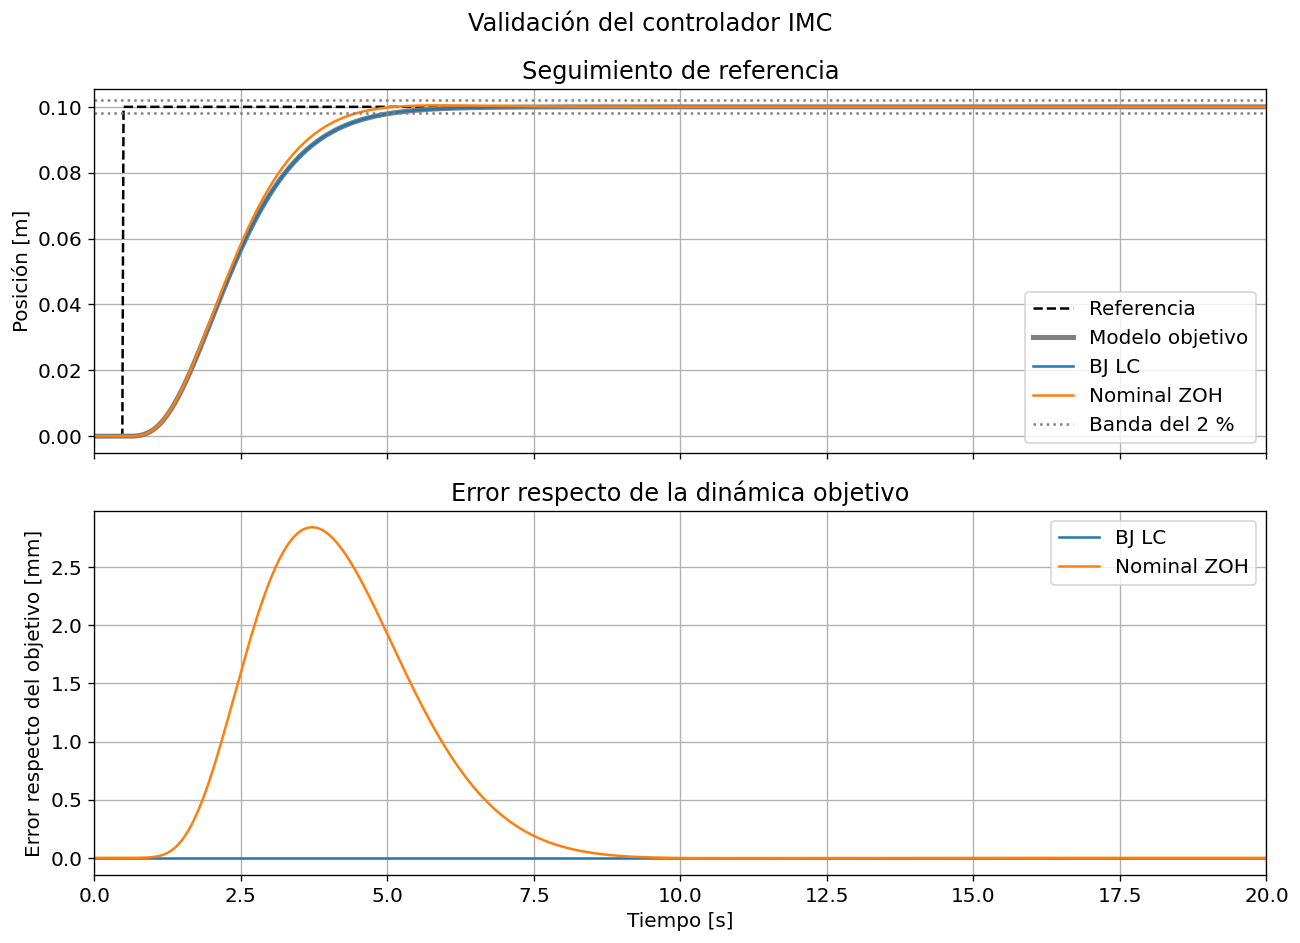

In [ ]:
#Seguimiento de referencia
# CELDA 60
# Seguimiento de referencia del IMC

fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

ax[0].plot(
    t_imc, ref_imc,
    "k--",
    label="Referencia"
)

ax[0].plot(
    t_imc, y_obj_imc,
    color="gray",
    linewidth=3,
    label="Modelo objetivo"
)

for nombre, datos in senales_imc.items():

    ax[0].plot(
        t_imc,
        datos["y"],
        linewidth=1.5,
        label=nombre
    )

    ax[1].plot(
        t_imc,
        1000*(datos["y"] - y_obj_imc),
        linewidth=1.5,
        label=nombre
    )

ax[0].axhline(
    0.102,
    color="gray",
    linestyle=":"
)

ax[0].axhline(
    0.098,
    color="gray",
    linestyle=":",
    label="Banda del 2 %"
)

ax[0].set_ylabel("Posición [m]")
ax[0].set_title("Seguimiento de referencia")

ax[1].set_ylabel("Error respecto del objetivo [mm]")
ax[1].set_xlabel("Tiempo [s]")
ax[1].set_title("Error respecto de la dinámica objetivo")

for a in ax:
    a.grid(True)
    a.legend()
    a.set_xlim(0, 20)

fig.suptitle(
    "Validación del controlador IMC"
)

plt.tight_layout()

plt.savefig(
    "imc_validacion_seguimiento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

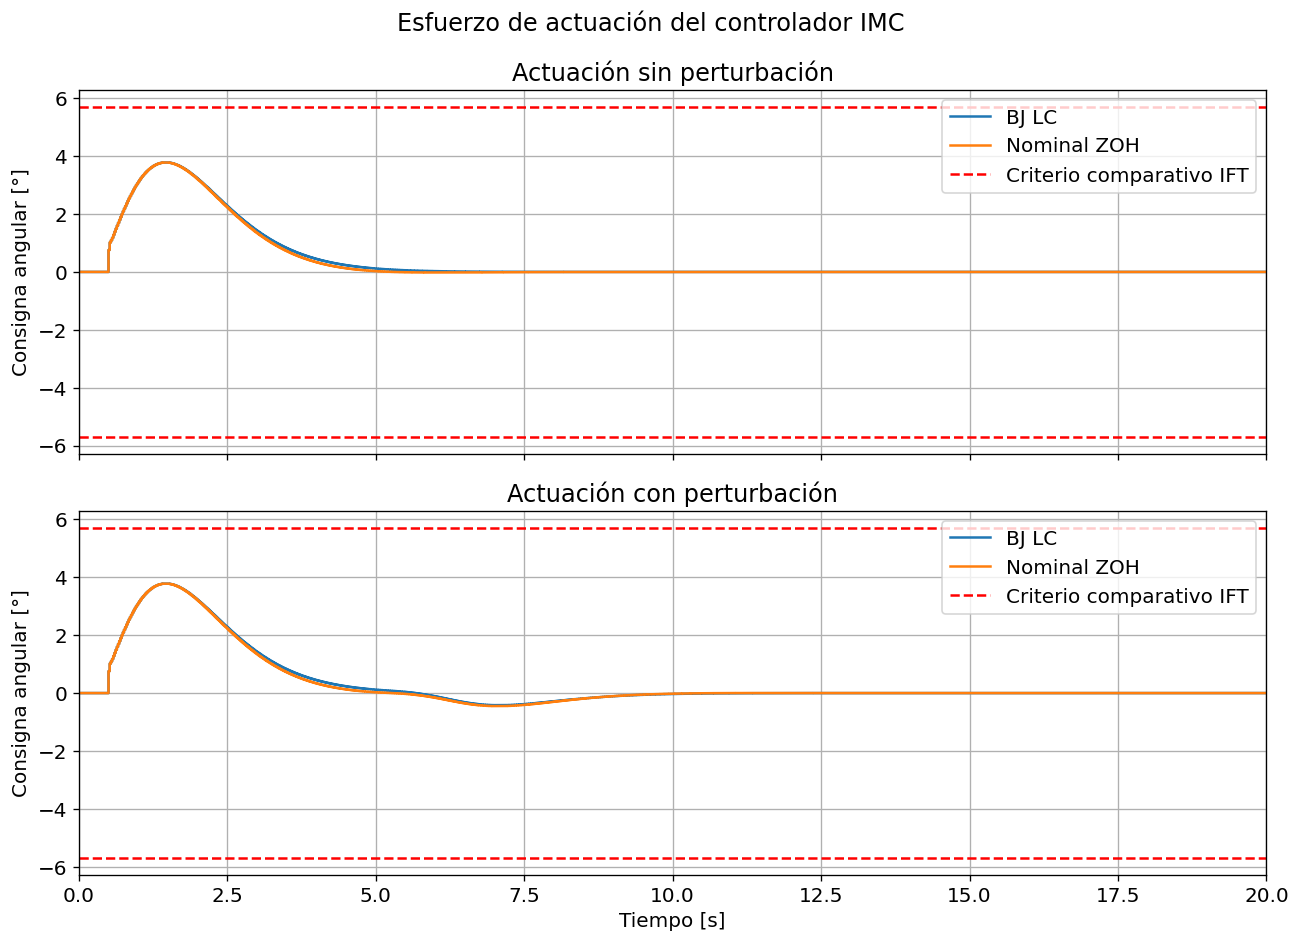

In [ ]:
#Acción de control
# CELDA 61
# Acción de control del IMC

fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

for nombre, datos in senales_imc.items():

    ax[0].step(
        t_imc,
        np.rad2deg(datos["u"]),
        where="post",
        linewidth=1.5,
        label=nombre
    )

    ax[1].step(
        t_imc,
        np.rad2deg(datos["u_total"]),
        where="post",
        linewidth=1.5,
        label=nombre
    )

ax[0].set_title("Actuación sin perturbación")
ax[1].set_title("Actuación con perturbación")

for a in ax:

    a.axhline(
        5.6975,
        color="red",
        linestyle="--",
        label="Criterio comparativo IFT"
    )

    a.axhline(
        -5.6975,
        color="red",
        linestyle="--"
    )

    a.set_ylabel("Consigna angular [°]")
    a.set_xlim(0, 20)
    a.grid(True)
    a.legend()

ax[1].set_xlabel("Tiempo [s]")

fig.suptitle(
    "Esfuerzo de actuación del controlador IMC"
)

plt.tight_layout()

plt.savefig(
    "imc_validacion_control.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

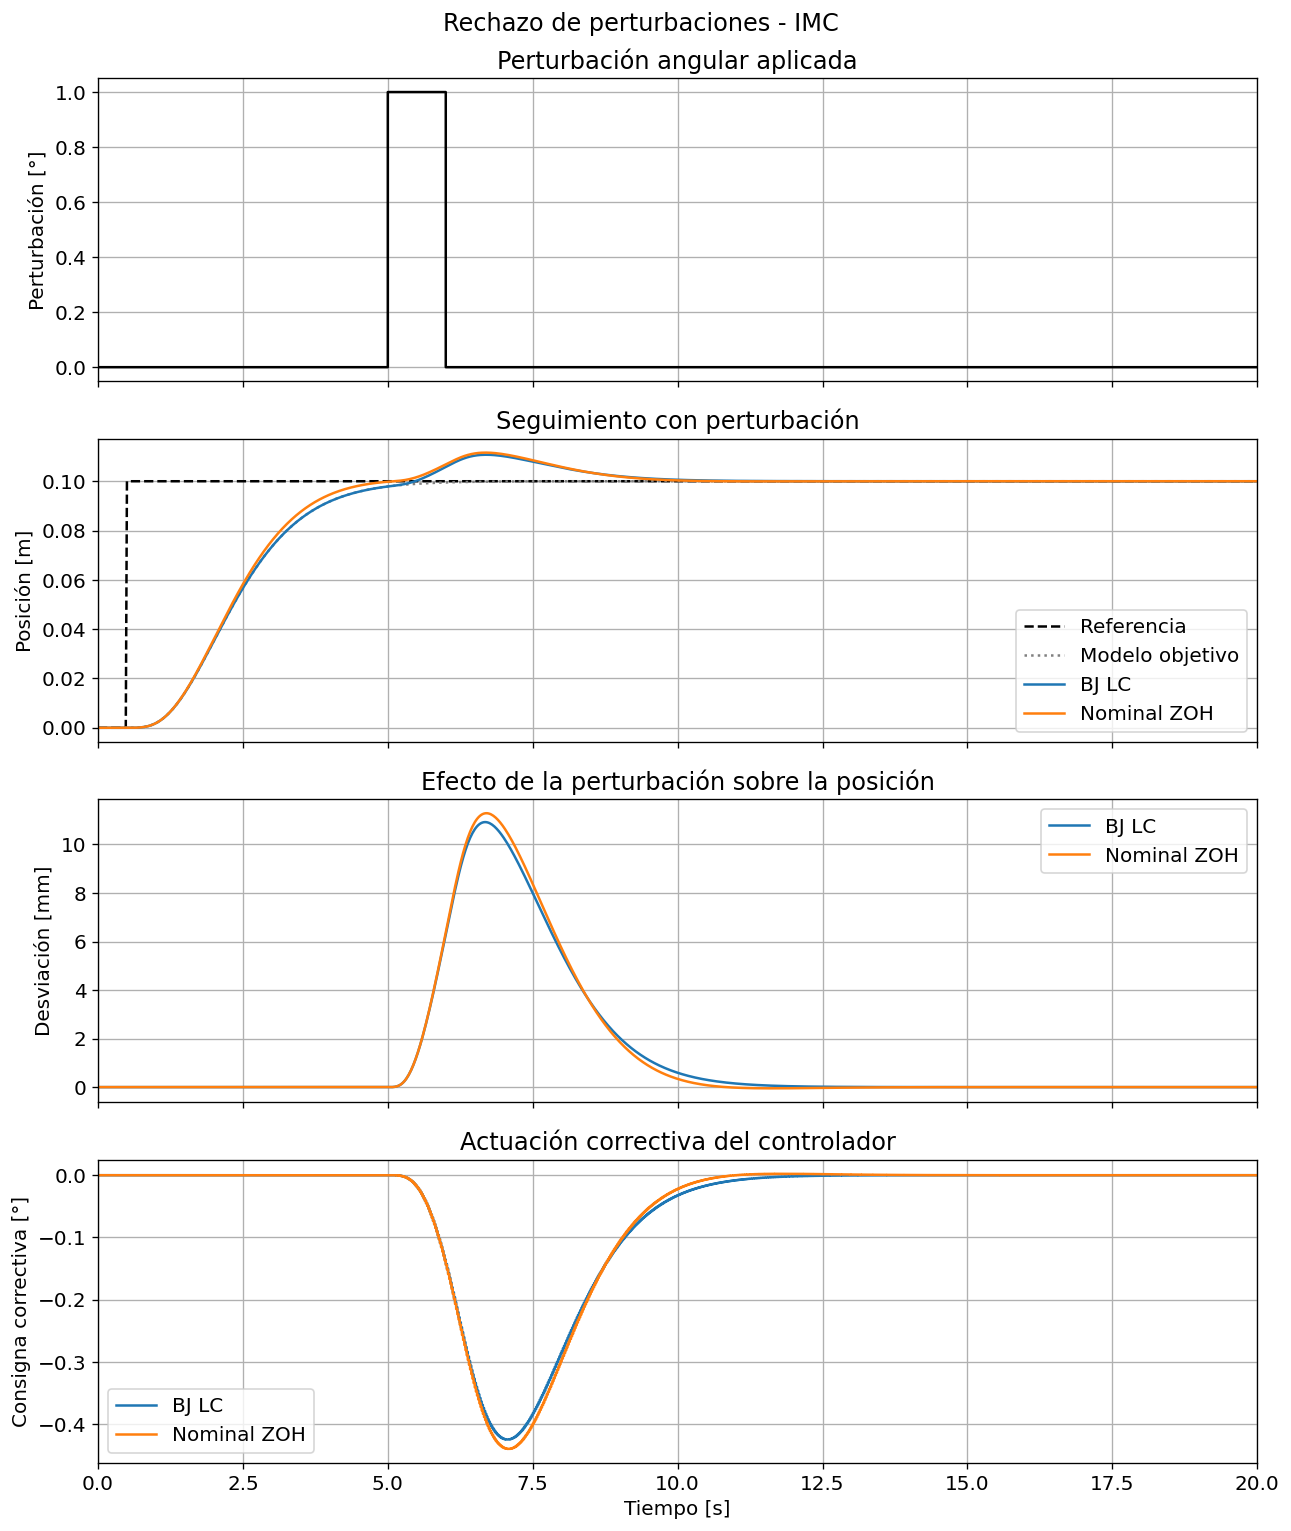

In [ ]:
#Rechazo de perturbaciones
# CELDA 62
# Rechazo de perturbaciones del IMC

fig, ax = plt.subplots(
    4, 1,
    figsize=(11, 13),
    sharex=True
)

# Perturbación aplicada

ax[0].step(
    t_imc,
    np.rad2deg(du_imc),
    where="post",
    color="black"
)

ax[0].set_ylabel("Perturbación [°]")
ax[0].set_title("Perturbación angular aplicada")

# Seguimiento con perturbación

ax[1].plot(
    t_imc,
    ref_imc,
    "k--",
    label="Referencia"
)

ax[1].plot(
    t_imc,
    y_obj_imc,
    color="gray",
    linestyle=":",
    label="Modelo objetivo"
)

for nombre, datos in senales_imc.items():

    ax[1].plot(
        t_imc,
        datos["y_total"],
        linewidth=1.5,
        label=nombre
    )

    # Desviación de posición

    ax[2].plot(
        t_imc,
        1000*datos["yd"],
        linewidth=1.5,
        label=nombre
    )

    # Actuación correctiva

    ax[3].step(
        t_imc,
        np.rad2deg(datos["ud"]),
        where="post",
        linewidth=1.5,
        label=nombre
    )

ax[1].set_ylabel("Posición [m]")
ax[1].set_title("Seguimiento con perturbación")

ax[2].set_ylabel("Desviación [mm]")
ax[2].set_title("Efecto de la perturbación sobre la posición")

ax[3].set_ylabel("Consigna correctiva [°]")
ax[3].set_title("Actuación correctiva del controlador")
ax[3].set_xlabel("Tiempo [s]")

for a in ax:
    a.grid(True)
    a.set_xlim(0, 20)

for a in ax[1:]:
    a.legend()

fig.suptitle(
    "Rechazo de perturbaciones - IMC"
)

plt.tight_layout()

plt.savefig(
    "imc_validacion_perturbacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Descarga de las figuras de validación SIMC-PID 2DOF

from google.colab import files

files.download("simc_2dof_validacion_temporal.png")
files.download("simc_2dof_validacion_perturbaciones.png")
files.download("simc_2dof_polos_lazo_cerrado.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>